# 01. 전처리 (preprocessing)

**이 노트북이 하는 일**

서울교통공사 지하철 승하차 원본과 기상청 ASOS 날씨 원본에서 **모델 입력 데이터(`model_input_9stations.csv`)까지** 만드는 전체 과정을 한 노트북에 모았습니다. 기존 `scripts/step1~9`의 코드를 그대로 셀로 옮겼습니다.

1. 원본 읽기·표준화  2. 역 이름 통일  3. 서울 소재 역과 시간대 표  4. 역 유형 분류  5. 일별 최종 표  6. 그림  7. 2025년(test) 행 추가(데이터 준비만)  8. ASOS 일별 날씨  9. 모델 입력 표

> **원본(`rawdata/`)이 없으면** 각 단계는 건너뛰고, 마지막의 "처리된 파일 읽기"만 실행됩니다. 원본은 저장소에 없으므로(용량) 아래 출처에서 받아 `rawdata/`에 두세요.

**입력 파일**

- `rawdata/` 지하철 승하차 원본: 서울 열린데이터광장 「서울교통공사_역별 일별 시간대별 승하차인원 정보」 (https://data.seoul.go.kr/dataList/OA-12921/F/1/datasetView.do), 공공데이터포털의 같은 자료(2024년까지, https://www.data.go.kr/data/15048032/fileData.do)
- `rawdata/asos/` 기상청 기상자료개방포털 종관기상관측(ASOS) 시간자료, 서울(108) 2014~2025 (연도별 csv, 매년 00~23시)
- 특보 파일 `서울_날씨특보_활성상태_일별_onehot.csv` (저장소 루트 또는 `rawdata/alert/`)

**출력 파일**

- `data/processed/` 아래: `station_daily.csv.gz`, `station_type.csv`, `weather_daily.csv`, **`model_input_9stations.csv`** 등 (파일 목록은 각 단계 끝에서 확인)
- `data/interim/raw_{연도}.pkl` (중간 파일), `figures/` (그림 3종)


**설정 불러오기**: Colab이면 저장소를 clone해 경로를 맞추고, `00_settings.ipynb`의 설정을 불러옵니다 (로컬이면 clone은 건너뜀).

In [1]:
# Colab에서 실행하면 저장소를 clone하고 notebooks/로 이동합니다 (로컬이면 건너뜁니다).
import os, sys, subprocess
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/TimeSeries'):
        subprocess.run(['git', 'clone', 'https://github.com/Eui-seung/TimeSeries.git', '/content/TimeSeries'], check=True)
    os.chdir('/content/TimeSeries/notebooks')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'holidays', 'factor_analyzer'], check=True)

# 설정(경로, 역, 열 이름, 기간, 차수 등)을 불러옵니다.
%run ./00_settings.ipynb

**필요한 파일 점검 도우미**: 단계가 끝날 때마다 산출물 파일의 행·열 수를 보여 줍니다 (없으면 "없음").

In [2]:
def show_files(names):
    """산출물 파일의 행·열 수를 표로 보여줍니다 (없으면 '없음')."""
    rows = []
    for n in names:
        p = PROC / n
        if p.exists():
            d = pd.read_csv(p)
            rows.append((n, len(d), d.shape[1]))
        else:
            rows.append((n, '없음', ''))
    return pd.DataFrame(rows, columns=['file', 'rows', 'cols'])

print('원본(rawdata) 있음:', RAW_OK)

원본(rawdata) 있음: True


## 공통 함수: 원본 읽기·정리

기존 `scripts/common.py`에서 경로·환경 설정(`00_settings`로 이동)을 뺀 나머지입니다. 연도별로 컬럼 구성이 다른 원본을 표준 컬럼으로 맞추는 함수들입니다.

필요한 패키지를 불러옵니다.

In [3]:
import os, re, sys, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd

필요한 패키지를 불러옵니다.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

**상수**: 학습·테스트 연도, 시간대 열 이름(`h05`~`h24`)과 영문 라벨을 정의합니다.

In [5]:
TRAIN_YEARS = list(range(2014, 2025))     # 학습 기간 2014~2024
TEST_YEARS = [2025]                       # 테스트 기간
HOURS = [f'h{i:02d}' for i in range(5, 25)]   # h05='06시 이전'(05~06 포함) … h24='24시 이후'
HOUR_LABELS = {'h05': 'before_06', 'h24': 'after_24', **{f'h{i:02d}': f'h{i:02d}_{i+1:02d}' for i in range(6, 24)}}
HLAB = [HOUR_LABELS[h] for h in HOURS]        # station_date_hour의 영문 시간대 열

**`ensure_dirs`**: 결과 폴더(처리 결과, 중간 파일, 그림)가 없으면 만듭니다.

In [6]:
def ensure_dirs():
    for p in (PROC, INTERIM, FIG):
        p.mkdir(parents=True, exist_ok=True)

**`nfc`**: 한글 파일명을 NFC로 정규화합니다 (macOS 파일명 조합 차이 해결).

In [7]:
def nfc(s):
    return unicodedata.normalize('NFC', s)

**`raw_file`**: 분석에 쓰는 연도별 원본 파일 하나를 고름 (겹치는 2023~2024년 다른 파일은 제외).

In [8]:
def raw_file(year):
    """분석에 쓰는 연도별 원본 파일 하나를 고름 (겹치는 2023~2024년 다른 파일은 제외)."""
    key = {2022: '20221231', 2023: '(23.1~23.12)', 2024: '(24.1~24.12)', 2025: '20251231'}.get(year, f'{year}년 일별 역별')
    hits = [f for f in os.listdir(RAW) if not f.startswith('.') and key in nfc(f)]
    if len(hits) != 1:
        raise FileNotFoundError(f'{year}년 원본 파일을 하나로 특정하지 못함: {hits}')
    return hits[0]

**`read_raw`**: 원본 파일을 컬럼 그대로 읽음 (csv: cp949, xlsx: 첫 '날짜' 행을 헤더로).

In [9]:
def read_raw(fname):
    """원본 파일을 컬럼 그대로 읽음 (csv: cp949, xlsx: 첫 '날짜' 행을 헤더로)."""
    p = RAW / fname
    if fname.endswith('.xlsx'):
        d = pd.read_excel(p, header=None, dtype=object)
        hr = [i for i in range(5) if '날짜' in [str(x).strip() for x in d.iloc[i]]][0]
        d.columns = [str(c).strip() for c in d.iloc[hr]]
        return d.iloc[hr + 1:].reset_index(drop=True)
    return pd.read_csv(p, encoding='cp949', dtype=object)

**`standardize`**: 연도마다 다른 컬럼 구성을 위치 기준으로 표준화 -> date,line,stn_no,name,io,daytype,h05..h24

In [10]:
def standardize(d):
    """연도마다 다른 컬럼 구성을 위치 기준으로 표준화 -> date,line,stn_no,name,io,daytype,h05..h24"""
    cols = list(d.columns)
    io_idx = max(i for i, c in enumerate(cols) if c in ('구분', '승하차구분'))
    P = lambda i: d.iloc[:, i]
    out = pd.DataFrame()
    out['date'] = P([i for i, c in enumerate(cols) if c in ('날짜', '수송일자')][0])
    li = [i for i, c in enumerate(cols) if c == '호선']
    out['line'] = P(li[0]) if li else None
    out['stn_no'] = P([i for i, c in enumerate(cols) if c.startswith('역번호') or c.startswith('고유역번호')][0])
    out['name'] = P([i for i, c in enumerate(cols) if c == '역명'][0])
    out['io'] = P(io_idx)
    di = [i for i, c in enumerate(cols) if c == '구분' and i < io_idx]
    out['daytype'] = P(di[0]) if di else None
    hc = cols[io_idx + 1:io_idx + 21]
    # 2021년: '23시 이후'가 23~24시와 24시 이후를 합친 단일 컬럼 (다음 컬럼은 합계)
    merged = (len(cols) > io_idx + 20 and str(cols[io_idx + 19]).replace(' ', '').endswith('이후')
              and str(cols[io_idx + 20]).replace(' ', '') == '합계')
    for k, h in enumerate(HOURS):
        out[h] = pd.NA if (merged and k == 19) else P(io_idx + 1 + k)
    out.attrs['merged_23_24'] = merged
    return out, hc

**`clean`**: 문자열 정리: 날짜·방향·이름·역번호·노선·숫자(쉼표 제거)

In [11]:
def clean(s, src):
    """문자열 정리: 날짜·방향·이름·역번호·노선·숫자(쉼표 제거)"""
    s = s.copy()
    s['date'] = pd.to_datetime(s['date'].astype(str).str.strip().str[:10])
    s['io'] = s['io'].astype(str).str.strip()
    s['name_raw'] = s['name'].astype(str).str.strip()
    s = s.drop(columns=['name'])
    s['stn_no'] = s['stn_no'].astype(str).str.strip()
    s['line'] = s['line'].astype(str).str.replace('호선', '').str.strip().replace({'None': None})
    for h in HOURS:
        s[h] = pd.to_numeric(s[h].astype(str).str.replace(',', '').str.strip(), errors='coerce')
    if '20221231' in nfc(src):
        s['h24'] = s['h24'].fillna(0)          # 2022년 1~5월 '24시이후' 빈칸은 0
    s['year'] = s.date.dt.year
    s['src'] = nfc(src)
    return s

**`load_year`**: 한 연도 원본 -> 정리된 표 (빈 행 제거). 반환: (표, 원본 컬럼 수, 원본 행 수)

In [12]:
def load_year(year):
    """한 연도 원본 -> 정리된 표 (빈 행 제거). 반환: (표, 원본 컬럼 수, 원본 행 수)"""
    f = raw_file(year)
    d = read_raw(f)
    n_raw = len(d)
    d = d.dropna(how='all')                    # 2025 파일 끝의 빈 행 등
    s, _ = standardize(d)
    s = clean(s, f)
    s.attrs['merged_23_24'] = s.attrs.get('merged_23_24', False)
    return s, n_raw

**`base_name`**: 괄호 부기명·공백 제거

In [13]:
def base_name(n):
    """괄호 부기명·공백 제거"""
    return re.sub(r'\s+', '', re.sub(r'\([^)]*\)', '', n))

**`strip_yeok`**: 끝의 '역' 제거 (정규화 키용, 서울역 -> 서울)

In [14]:
def strip_yeok(n):
    """끝의 '역' 제거 (정규화 키용, 서울역 -> 서울)"""
    return n[:-1] if n.endswith('역') and len(n) >= 3 else n

**`load_interim`**: step1이 저장한 연도별 표를 합침. 2014~2016(노선 컬럼 없음)은 역번호로 노선을 채우고,

In [15]:
def load_interim(years):
    """step1이 저장한 연도별 표를 합침. 2014~2016(노선 컬럼 없음)은 역번호로 노선을 채우고,
    빈 역번호는 같은 (노선, 이름)의 번호로 채움."""
    A = pd.concat([pd.read_pickle(INTERIM / f'raw_{y}.pkl') for y in years], ignore_index=True)
    ref = None
    for y in range(2017, 2030):
        p = INTERIM / f'raw_{y}.pkl'
        if p.exists():
            r = pd.read_pickle(p)[['stn_no', 'line']].dropna()
            ref = r.drop_duplicates('stn_no').set_index('stn_no').line
            break
    if ref is None and A.line.isna().any():
        raise RuntimeError('노선 보충용 2017년 이후 자료가 없음: step1을 먼저 실행')
    if ref is not None:
        A['line'] = A.line.fillna(A.stn_no.map(ref))
    assert A.line.notna().all(), '노선을 채우지 못한 행이 있음'
    A['line'] = A.line.astype(int)
    A['base'] = A.name_raw.map(base_name)
    blank = A.stn_no == ''
    if blank.any():
        fix = A[~blank].drop_duplicates(['line', 'base']).set_index(['line', 'base']).stn_no
        A.loc[blank, 'stn_no'] = [fix[(l, b)] for l, b in zip(A.loc[blank, 'line'], A.loc[blank, 'base'])]
    A['tot'] = A[HOURS].sum(axis=1)
    return A

## 1단계: 원본 파일 구조 확인 + 연도별 표준화

1단계: 원본 파일 구조 확인 + 연도별 표준화.

- 분석에 쓰는 연도별 원본을 읽어 표준 컬럼으로 정리해 data/interim/raw_{year}.pkl 로 저장
- 모든 원본 파일(분석 제외 파일 포함)의 구조 요약을 file_structure.csv 로 저장 (--years를 주지 않았을 때)

필요한 패키지를 불러옵니다.

In [16]:
import pandas as pd
import chardet

**`profile_file`**: 원본 파일 하나의 구조(행 수, 기간, 노선 열 유무, 역 수, 시간대 수)를 요약합니다.

In [17]:
def profile_file(fname):
    d = read_raw(fname)
    s, hc = standardize(d.dropna(how='all'))
    s = clean(s, fname)
    ds = pd.DatetimeIndex(sorted(s.date.unique()))
    miss = pd.date_range(ds.min(), ds.max()).difference(ds)
    lines = sorted(s.line.dropna().astype(str).unique())
    return dict(file=nfc(fname)[:-4] if fname.endswith('.csv') else nfc(fname)[:-5],
                format='xlsx' if fname.endswith('.xlsx') else 'csv(cp949)', n_rows=len(d),
                start_date=ds.min().date(), end_date=ds.max().date(), n_days=len(ds), n_missing_days=len(miss),
                has_line_column=bool(s.line.notna().any()), line_list=','.join(lines) or '(없음)',
                n_station_names=s.name_raw.nunique(), n_time_bins=19 if s.attrs.get('merged_23_24') else 20)

**`main`**: 연도별 원본을 표준화해 `data/interim/raw_{연도}.pkl`로 저장하고, 모든 원본 파일의 구조 요약(`file_structure.csv`)을 만듭니다.

In [18]:
def main(years=None):
    ensure_dirs()
    given = years
    years = given or TRAIN_YEARS
    for y in years:
        s, n_raw = load_year(y)
        s.to_pickle(INTERIM / f'raw_{y}.pkl')
        print(f'{y}: 원본 {n_raw:,}행 -> 사용 {len(s):,}행 | {s.date.min().date()}~{s.date.max().date()} | 파일 {s.src.iloc[0][:40]}')
    if not given:
        files = sorted([f for f in os.listdir(RAW) if not f.startswith('.') and (RAW / f).is_file()], key=nfc)
        files = [f for f in files if not any(k in nfc(f) for k in ['20251231'])]   # 테스트 연도는 step7에서 다룸
        rows = [profile_file(f) for f in files]
        pd.DataFrame(rows).to_csv(PROC / 'file_structure.csv', index=False, encoding='utf-8-sig')
        print('file_structure.csv 저장 (파일', len(rows), '개)')

**실행** (원본이 있을 때만): 2014~2024 원본을 표준화하고 구조 요약을 저장합니다.

In [19]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

2014: 원본 200,750행 -> 사용 200,750행 | 2014-01-01~2014-12-31 | 파일 서울교통공사 2014년 일별 역별 시간대별 승하차인원(1~8호선).csv


2015: 원본 200,750행 -> 사용 200,750행 | 2015-01-01~2015-12-31 | 파일 서울교통공사 2015년 일별 역별 시간대별 승하차인원(1~8호선).csv


2016: 원본 201,300행 -> 사용 201,300행 | 2016-01-01~2016-12-31 | 파일 서울교통공사 2016년 일별 역별 시간대별 승하차인원(1~8호선).csv


2017: 원본 200,750행 -> 사용 200,750행 | 2017-01-01~2017-12-31 | 파일 서울교통공사 2017년 일별 역별 시간대별 승하차인원(1_8호선).xls


2018: 원본 200,750행 -> 사용 200,750행 | 2018-01-01~2018-12-31 | 파일 서울교통공사 2018년 일별 역별 시간대별 승하차인원(1_8호선).xls


2019: 원본 200,804행 -> 사용 200,804행 | 2019-01-01~2019-12-31 | 파일 서울교통공사 2019년 일별 역별 시간대별 승하차인원(1_8호선).xls


... (2 outputs left out)

2022: 원본 199,080행 -> 사용 199,080행 | 2022-01-01~2022-12-31 | 파일 서울교통공사_역별 일별 시간대별 승하차인원 정보_20221231.csv


2023: 원본 199,270행 -> 사용 199,270행 | 2023-01-01~2023-12-31 | 파일 서울교통공사_역별 시간대별 승하차인원(23.1~23.12).csv


2024: 원본 199,410행 -> 사용 199,410행 | 2024-01-01~2024-12-31 | 파일 서울교통공사_역별 시간대별 승하차인원(24.1~24.12).csv


file_structure.csv 저장 (파일 14 개)


산출물 확인

In [20]:
show_files(['file_structure.csv'])

,file,rows,cols
0,file_structure.csv,14,11


## 2단계: 역명 통일

2단계: 역명 통일.

- 괄호 부기명·공백·끝의 '역'을 제거한 정규화 이름으로 연도별 (노선, 이름)을 비교
- 이름 변경 후보(rename_candidates.csv), 신설·소멸 역(new_closed_stations.csv),
  환승역 통합까지 반영한 station_map.csv(원본명, 노선, 표준역명=가장 최근 이름, 시작·종료일) 생성
- 학습 기간(2014~2024)만 사용. 일 합계 > 0인 날을 '존재'로 봄.

상수·설정값을 정의합니다: `MANUAL_TRANSFER`, `PREFERRED_STANDARD`, `PLACEHOLDER_MIN_DAYS`, `MAX_GAP_DAYS`, `WIN`.

In [21]:
# 이름이 달라도 같은 환승역으로 묶을 쌍 (확정: 4호선 총신대입구(이수) = 7호선 이수).
# 6호선 새절(신사) ↔ 3호선 신사는 별개 역이라 묶지 않음.
MANUAL_TRANSFER = [((4, '총신대입구'), (7, '이수'))]
PREFERRED_STANDARD = {'이수'}          # 표준역명 동률일 때 우선할 이름
PLACEHOLDER_MIN_DAYS = 30              # 유효일수가 이보다 적으면 자리표시 행으로 봄
MAX_GAP_DAYS = 31                      # 이름 변경 후보: 사라진 날과 생긴 날의 최대 간격
WIN = 28                               # 이름 변경 전후 일평균 승차 계산 일수

**`main`**: 원본 역 이름 → 표준역명 대응표(`station_map.csv`), 이름 변경 후보, 신설·소멸 역 표를 만듭니다.

In [22]:
def main():
    ensure_dirs()
    A = load_interim(TRAIN_YEARS)
    A['norm'] = A.base.map(strip_yeok)
    act = A[A.tot > 0]
    START, END = A.date.min(), A.date.max()

    # (노선, 원본명) 단위 요약
    raw_all = A.groupby(['line', 'name_raw']).agg(rows=('date', 'size'), first_all=('date', 'min'), last_all=('date', 'max')).reset_index()
    raw_act = act.groupby(['line', 'name_raw']).agg(first=('date', 'min'), last=('date', 'max'), days=('date', 'nunique')).reset_index()
    R = raw_all.merge(raw_act, on=['line', 'name_raw'], how='left')
    R['days'] = R.days.fillna(0).astype(int)
    nm = A.drop_duplicates(['line', 'name_raw'])[['line', 'name_raw', 'stn_no', 'base', 'norm']]
    R = R.merge(nm, on=['line', 'name_raw'])
    R['first'] = R['first'].fillna(R.first_all)
    R['last'] = R['last'].fillna(R.last_all)
    # (노선, 부기명 제거 이름) 단위
    N = R.groupby(['line', 'base', 'norm']).agg(first=('first', 'min'), last=('last', 'max'), days=('days', 'sum'), stn_no=('stn_no', 'first')).reset_index()
    N['placeholder'] = N.days < PLACEHOLDER_MIN_DAYS

    # ---- 이름 변경 후보: 같은 노선에서 사라진 이름과 새로 생긴 이름의 짝 (역번호가 같으면 우선)
    good = N[~N.placeholder]
    old = good[good['last'] < END]
    new = good[good['first'] > START]
    dayq = act[act.io == '승차'].groupby(['line', 'base', 'date']).tot.sum()

    def avg(l, b, a, z):
        s = dayq.loc[(l, b)]
        s = s[(s.index >= a) & (s.index <= z)]
        return round(s.mean(), 1) if len(s) else np.nan

    rows = []
    for _, o in old.iterrows():
        for _, n in new[new.line == o.line].iterrows():
            gap = (n['first'] - o['last']).days
            same = o.stn_no == n.stn_no
            if same or 0 <= gap <= MAX_GAP_DAYS:
                b = avg(o.line, o.base, o['last'] - pd.Timedelta(days=WIN - 1), o['last'])
                a = avg(n.line, n.base, n['first'], n['first'] + pd.Timedelta(days=WIN - 1))
                rows.append(dict(line=o.line, old_name=o.base, new_name=n.base, old_last_date=o['last'].date(), new_first_date=n['first'].date(),
                                 change_period=str(n['first'].date())[:7], gap_days=gap, old_station_no=o.stn_no, new_station_no=n.stn_no, same_station_no=same,
                                 basis=('역번호 동일' + (' + 시기 인접' if 0 <= gap <= MAX_GAP_DAYS else '')) if same else '같은 노선·시기 인접(역번호 다름)',
                                 avg_daily_boarding_28d_before=b, avg_daily_boarding_28d_after=a,
                                 change_rate=round(a / b - 1, 3) if b == b and a == a and b else np.nan,
                                 matches_file_boundary=(str(o['last'].date()) == '2016-12-31')))
    RC = pd.DataFrame(rows).sort_values(['same_station_no', 'change_period'], ascending=[False, True])
    RC.to_csv(PROC / 'rename_candidates.csv', index=False, encoding='utf-8-sig')

    # ---- 같은 역 묶기 (union-find): 역번호 동일(개명) / 다른 노선 같은 정규화 이름(환승) / 수동 지정
    nodes = list(zip(N.line, N.base))
    par = {n: n for n in nodes}

    def find(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x

    def union(a, b):
        par[find(a)] = find(b)

    for _, d in N.groupby('stn_no'):
        ns = list(zip(d.line, d.base))
        for a, b in zip(ns, ns[1:]):
            union(a, b)
    for _, d in N.groupby('norm'):
        ns = list(zip(d.line, d.base))
        for a, b in zip(ns, ns[1:]):
            union(a, b)
    for a, b in MANUAL_TRANSFER:
        union(a, b)
    N['grp'] = [find(n) for n in nodes]
    std = {}
    for g, d in N.groupby('grp'):
        d2 = d[~d.placeholder] if (~d.placeholder).any() else d
        c = d2[d2['last'] == d2['last'].max()]                      # 표준역명 = 가장 최근까지 쓰인 이름
        pick = c[c.base.isin(PREFERRED_STANDARD)] if c.base.isin(PREFERRED_STANDARD).any() else c
        std[g] = pick.base.iloc[0]
    N['station'] = N.grp.map(std)

    SM = R.merge(N[['line', 'base', 'grp', 'station', 'placeholder']], on=['line', 'base'])
    SM['note'] = np.where(SM.placeholder, '값 전부(거의) 0인 자리표시 행 - 유효 데이터 없음',
                          np.where((SM.days < SM.rows / 2 * 0.99) & (SM.days > 0) & (SM['last_all'] > SM['last']), '종료일 이후 값 0인 잔여 행 존재', ''))
    SM = SM.rename(columns={'name_raw': 'raw_name', 'norm': 'normalized_name', 'stn_no': 'station_no', 'first': 'start_date', 'last': 'end_date', 'days': 'valid_days'})
    SM['transfer_group_line_count'] = SM.grp.map(N.groupby('grp').line.nunique())
    SM = SM[['raw_name', 'normalized_name', 'line', 'station_no', 'station', 'start_date', 'end_date', 'valid_days', 'transfer_group_line_count', 'note']]
    SM = SM.sort_values(['station', 'line', 'start_date'])
    SM['start_date'] = SM.start_date.dt.date
    SM['end_date'] = SM.end_date.dt.date
    SM.to_csv(PROC / 'station_map.csv', index=False, encoding='utf-8-sig')     # in_seoul 열은 step3에서 추가

    # ---- 신설·소멸 역 (이름 변경이 아닌 것)
    G = N[~N.placeholder]
    nc = []
    for (l, s), d in G.groupby(['line', 'station']):
        f0, l0 = d['first'].min(), d['last'].max()
        if f0 > START:
            nc.append(dict(station=s, line=l, category='신설', first_date=f0.date(), last_date=l0.date(), note='이전 이름 없음(이름 변경 아님)'))
        if l0 < END:
            nc.append(dict(station=s, line=l, category='자료상 소멸', first_date=f0.date(), last_date=l0.date(),
                           note='2022년 이후 값 없음(잔여 0값 행만 존재). 폐역이 아니라 집계 제외로 추정 - 원인 확인 필요' if l == 7 else ''))
    pd.DataFrame(nc).drop_duplicates().to_csv(PROC / 'new_closed_stations.csv', index=False, encoding='utf-8-sig')
    print('station_map', len(SM), '행 / 표준역명', SM.station.nunique(), '개 | 이름 변경 후보', len(RC), '건 | 신설·소멸', len(nc), '건')

**실행** (원본이 있을 때만)

In [23]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

station_map 482 행 / 표준역명 249 개 | 이름 변경 후보 3 건 | 신설·소멸 16 건


산출물 확인

In [24]:
show_files(['station_map.csv', 'rename_candidates.csv', 'new_closed_stations.csv'])

,file,rows,cols
0,station_map.csv,482,10
1,rename_candidates.csv,3,15
2,new_closed_stations.csv,16,6


## 3단계: 역명 통일 적용 + 서울 외 역 제외 + 시간대 테이블

3단계: 역명 통일 적용 + 서울 외 역 제외 + 시간대 테이블.

- station_map(표준역명)으로 전체 자료의 이름을 바꾸고, 환승역은 노선을 합산
- 서울 외 소재 역(EXCLUDED)을 제외하고 excluded_stations.csv 저장, station_map에 in_seoul 열 추가
- 역×날짜×방향별 20개 시간대 테이블(station_date_hour.csv.gz) 저장
- 승차 또는 하차 한쪽만 0인 날은 집계 오류로 보고 0인 방향의 시간대 값을 NaN으로 바꿈
- 매년 존재하는 역 목록(always_present_stations.csv), 연도별 존재 일수(station_presence_by_year.csv)

상수·설정값을 정의합니다: `EXCLUDED`.

In [25]:
# 서울 외 소재 역: (노선, 표준역명) -> (소재지, 확인방식). 소재지는 역 주소(웹 문서)로 확인.
W, K = '웹 문서 확인(itwiki.kr)', '행정구역상 명확(개별 문서 미확인)'
EXCLUDED = {
    (3, '지축'): ('경기도 고양시 덕양구 지축동', '웹 검색 확인(지축동 소재)'),
    (5, '미사'): ('경기도 하남시', K), (5, '하남풍산'): ('경기도 하남시', K), (5, '하남시청'): ('경기도 하남시', K), (5, '하남검단산'): ('경기도 하남시', K),
    (7, '장암'): ('경기도 의정부시 장암동', W), (7, '철산'): ('경기도 광명시', W), (7, '광명사거리'): ('경기도 광명시', K),
    (7, '까치울'): ('경기도 부천시', W), (7, '부천종합운동장'): ('경기도 부천시', W), (7, '춘의'): ('경기도 부천시', W), (7, '신중동'): ('경기도 부천시', W),
    (7, '부천시청'): ('경기도 부천시', W), (7, '상동'): ('경기도 부천시', W),
    (7, '삼산체육관'): ('인천광역시 부평구', W), (7, '굴포천'): ('인천광역시 부평구', W), (7, '부평구청'): ('인천광역시 부평구', W),
    (8, '남위례'): ('경기도 성남시 수정구 복정동', W), (8, '산성'): ('경기도 성남시', W), (8, '남한산성입구'): ('경기도 성남시', W),
    (8, '단대오거리'): ('경기도 성남시', W), (8, '신흥'): ('경기도 성남시', W), (8, '수진'): ('경기도 성남시', W), (8, '모란'): ('경기도 성남시', W),
}

**`write_excluded_and_flag`**: 서울 외 소재 역을 표시하고 `excluded_stations.csv`를 저장합니다.

In [26]:
def write_excluded_and_flag(SM):
    SM = SM.drop(columns=[c for c in ('in_seoul', 'exclusion_reason') if c in SM.columns])
    SM['in_seoul'] = ['N' if (l, s) in EXCLUDED else 'Y' for l, s in zip(SM.line, SM.station)]
    SM['exclusion_reason'] = ['서울 외 소재' if (l, s) in EXCLUDED else '' for l, s in zip(SM.line, SM.station)]
    g = SM.groupby(['line', 'station']).agg(station_no=('station_no', 'first'), first_date=('start_date', 'min'), last_date=('end_date', 'max')).reset_index()
    rows = []
    for (l, s), (addr, how) in EXCLUDED.items():
        r = g[(g.line == l) & (g.station == s)]
        assert len(r) == 1, ('station_map에 없는 제외 역', l, s)
        r = r.iloc[0]
        rows.append(dict(station=s, line=l, station_no=r.station_no, location=addr, exclusion_reason='서울 외 소재', verification=how, first_date=r.first_date, last_date=r.last_date))
    pd.DataFrame(rows).sort_values(['line', 'station_no']).to_csv(PROC / 'excluded_stations.csv', index=False, encoding='utf-8-sig')
    return SM

**`build_hourly`**: A(정리된 원자료, base 열 포함) -> 표준역명×날짜×방향 시간대 표 (서울 소재 역만, 환승 합산).

In [27]:
def build_hourly(A, SM):
    """A(정리된 원자료, base 열 포함) -> 표준역명×날짜×방향 시간대 표 (서울 소재 역만, 환승 합산)."""
    mp = SM[['raw_name', 'line', 'station', 'in_seoul']].rename(columns={'raw_name': 'name_raw'})
    B = A.merge(mp, on=['name_raw', 'line'], how='left')
    unmapped = B[B.station.isna()][['line', 'name_raw']].drop_duplicates()
    if len(unmapped):
        raise RuntimeError(f'station_map에 없는 (노선, 원본명): {unmapped.values.tolist()}')
    S = B[B.in_seoul == 'Y']
    T = S.groupby(['station', 'date', 'io'])[HOURS].sum(min_count=1).reset_index()
    assert abs(T[HOURS].sum().sum() - S[HOURS].sum().sum()) < 1
    # 역-일 합계가 0인 행 제거 (개통 전·자리표시 행 등)
    dd = T.groupby(['station', 'date'])[HOURS].sum(min_count=1).sum(axis=1)
    zero = set(dd[dd == 0].index)
    T = T[[(a, b) not in zero for a, b in zip(T.station, T.date)]].copy()
    # 승차 또는 하차 한쪽만 0 (합계>0): 집계 오류 -> 0인 방향 시간대 값을 NaN
    tot = T.assign(v=T[HOURS].sum(axis=1)).pivot(index=['station', 'date'], columns='io', values='v')
    one = tot[((tot['승차'] == 0) ^ (tot['하차'] == 0)) & ((tot['승차'] + tot['하차']) > 0)]
    T['flag_one_side_zero_set_nan'] = 0
    for (s, dt), r in one.iterrows():
        io = '승차' if r['승차'] == 0 else '하차'
        m = (T.station == s) & (T.date == dt) & (T.io == io)
        T.loc[m, HOURS] = np.nan
        T.loc[m, 'flag_one_side_zero_set_nan'] = 1
    T['flag_23plus_merged'] = (T.date.dt.year == 2021).astype(int)
    T = T.rename(columns={**HOUR_LABELS, 'io': 'direction'})
    T = T[['station', 'date', 'direction'] + HLAB + ['flag_23plus_merged', 'flag_one_side_zero_set_nan']]
    return T.sort_values(['station', 'date', 'direction']), len(zero), one

**`main`**: 표준역명을 적용해 서울 소재 역의 시간대 테이블(`station_date_hour.csv.gz`), 연도별 존재 일수, 매년 존재하는 역 목록을 만듭니다.

In [28]:
def main():
    ensure_dirs()
    SM = pd.read_csv(PROC / 'station_map.csv')
    SM = write_excluded_and_flag(SM)
    SM.to_csv(PROC / 'station_map.csv', index=False, encoding='utf-8-sig')
    print('서울 외 제외', len(EXCLUDED), '개 노선-역 / 남은 표준역명', SM[SM.in_seoul == 'Y'].station.nunique())
    A = load_interim(TRAIN_YEARS)
    T, n_zero, one = build_hourly(A, SM)
    print('역-일 합계 0 제거:', n_zero, '| 한쪽만 0 NaN 처리:', len(one), '|', T.shape)
    out = T.copy()
    out['date'] = out.date.dt.date
    out.to_csv(PROC / 'station_date_hour.csv.gz', index=False, encoding='utf-8-sig', compression='gzip')
    # 존재 일수
    P = T[T.direction == '승차'].assign(year=lambda x: x.date.dt.year).groupby(['station', 'year']).size().unstack(fill_value=0)
    P.to_csv(PROC / 'station_presence_by_year.csv', encoding='utf-8-sig')
    full = P[(P >= 300).all(axis=1)]
    pd.DataFrame({'station': full.index, 'n_years': len(TRAIN_YEARS), 'min_days_per_year': full.min(axis=1).values}).to_csv(PROC / 'always_present_stations.csv', index=False, encoding='utf-8-sig')
    print('매년 존재하는 역:', len(full), '/', len(P))

**실행** (원본이 있을 때만)

In [29]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

서울 외 제외 24 개 노선-역 / 남은 표준역명 225


역-일 합계 0 제거: 104 | 한쪽만 0 NaN 처리: 4 | (1787058, 25)


매년 존재하는 역: 222 / 224


산출물 확인

In [30]:
show_files(['station_map.csv', 'excluded_stations.csv', 'station_presence_by_year.csv', 'always_present_stations.csv', 'station_date_hour.csv.gz'])

,file,rows,cols
0,station_map.csv,482,12
1,excluded_stations.csv,24,8
2,station_presence_by_year.csv,224,12
3,always_present_stations.csv,222,3
4,station_date_hour.csv.gz,1787058,25


## 4단계: 역 유형 분류 (성현곤·김태현 2005 방식)

4단계: 역 유형 분류 (성현곤·김태현 2005 방식).

- 자료: 2014~2019, 2023~2024년 3월의 공휴일(3/1) 아닌 평일·토·일 → 역별 요일×5시간대×승/하차 = 30개 변수(일평균 이용객 수)
  연도별 일평균을 만든 뒤 사용 연도들의 평균을 역별 값으로 사용
- 분석: PCA(고유값>1 → 3요인) + oblimin 회전(패턴 행렬), 요인점수는 회귀 방식(SPSS 기본)
- 분류: 요인점수 ≥ 1인 요인이 그 역의 기능. 2개 이상이면 복합형, 모두 1 미만이면 미분류.
  3월 존재 연도가 2개 미만이면 분류 제외
- 출력: station_type.csv, station_type_lists.csv, step4_table2/3/4_comparison.csv, yearly_*.csv, station_type_change_vs_2005.csv

필요한 패키지를 불러옵니다.

In [31]:
import itertools
from scipy import stats
from factor_analyzer.rotator import Rotator

상수·설정값을 정의합니다: `CLASS_YEARS`, `BINS`, `BO`, `DAYS`, `IO`, `VARS`, `FN`, `PAPER`, `PAPER_EIG`, `PAPER_CUM`, `T4`, `ALIAS`, `FIG4`.

In [32]:
CLASS_YEARS = [2014, 2015, 2016, 2017, 2018, 2019, 2023, 2024]
BINS = {'09시이전': ['before_06', 'h06_07', 'h07_08', 'h08_09'], '09-12': ['h09_10', 'h10_11', 'h11_12'],
        '12-18': ['h12_13', 'h13_14', 'h14_15', 'h15_16', 'h16_17', 'h17_18'], '18-21': ['h18_19', 'h19_20', 'h20_21'],
        '21시이후': ['h21_22', 'h22_23', 'h23_24', 'after_24']}
BO = list(BINS)
DAYS = ['평일', '토', '일']
IO = ['승차', '하차']
VARS = [f'{d}_{b}_{i}' for d in DAYS for b in BO for i in IO]
FN = ['상업·여가', '주거', '고용']
# 논문 표 3 (PDF 8쪽, 0.5 이상 패턴 행렬 적재량): 변수 -> {요인: 적재량}
PAPER = {
    '일_21시이후_승차': {1: 1.011}, '일_18-21_승차': {1: .971}, '일_12-18_하차': {1: .953}, '토_21시이후_승차': {1: .925}, '토_12-18_하차': {1: .821},
    '토_18-21_승차': {1: .805}, '일_18-21_하차': {1: .683, 2: .507}, '토_18-21_하차': {1: .676}, '일_12-18_승차': {1: .651}, '일_09-12_하차': {1: .558}, '토_12-18_승차': {1: .52},
    '평일_09시이전_승차': {2: 1.084}, '토_09시이전_승차': {2: 1.057}, '평일_21시이후_하차': {2: .978}, '일_09시이전_승차': {2: .978}, '일_09-12_승차': {2: .952}, '토_09-12_승차': {2: .9},
    '일_21시이후_하차': {2: .883}, '평일_09-12_승차': {2: .874}, '토_21시이후_하차': {2: .851}, '평일_18-21_하차': {2: .622},
    '평일_09시이전_하차': {3: 1.09}, '토_09시이전_하차': {3: .949}, '평일_18-21_승차': {3: .857}, '평일_09-12_하차': {3: .844}, '평일_12-18_승차': {3: .641}, '토_09-12_하차': {3: .603},
    '평일_21시이후_승차': {1: .51, 3: .553}, '평일_12-18_하차': {3: .501}}
PAPER_EIG = [21.947, 5.496, 1.14, 0.533, 0.219, 0.15, 0.114, 0.08, 0.065, 0.056]
PAPER_CUM = [73.156, 91.475, 95.273, 97.05, 97.779, 98.28, 98.661, 98.928, 99.146, 99.333]
# 논문 표 4 (PDF 8쪽): 요인별 점수 1 이상 역 {요인: {역: 점수}}
T4 = {
    1: {'강남': 3.5, '강변': 2.9, '건대입구': 2.0, '고속터미널': 5.0, '노원': 1.52, '동대문': 2.0, '동대문운동장': 3.7, '명동': 3.4, '사당': 1.7, '삼성': 3.0, '서울대입구': 1.2, '서울역': 2.3, '신림': 2.1, '신촌': 3.9, '압구정': 1.3, '을지로입구': 2.0, '잠실': 3.4, '종각': 2.1, '종로3가': 3.2, '천호': 1.26, '청량리': 1.6, '혜화': 3.1, '홍대입구': 1.7},
    2: {'강남': 1.3, '강변': 2.2, '건대입구': 2.2, '고속터미널': 1.6, '광명사거리': 1.3, '구로디지털단지': 2.6, '까치산': 1.8, '낙성대': 1.2, '노원': 2.1, '당산': 1.7, '대림': 2.1, '미아삼거리': 2.2, '봉천': 1.0, '사당': 3.2, '상계': 1.3, '상봉': 1.1, '서울대입구': 2.5, '서울역': 1.4, '수유': 3.2, '신도림': 1.2, '신림': 5.1, '신촌': 1.3, '쌍문': 2.3, '연신내': 2.2, '이수': 1.8, '잠실': 2.9, '창동': 1.8, '천호': 1.3, '청량리': 2.3, '홍대입구': 1.3, '화곡': 1.7},
    3: {'강남': 4.6, '고속터미널': 2.2, '광화문': 1.5, '교대': 2.8, '구로디지털단지': 1.0, '남부터미널': 1.4, '동대문': 2.0, '동대문운동장': 1.3, '사당': 1.8, '삼성': 4.2, '서울역': 2.3, '선릉': 3.4, '시청': 2.9, '신촌': 1.0, '압구정': 2.0, '양재': 2.5, '여의도': 1.6, '역삼': 3.2, '을지로3가': 1.5, '을지로4가': 1.0, '을지로입구': 2.1, '잠실': 2.5, '종각': 1.7, '종로3가': 2.6, '종로5가': 1.1, '청담': 1.1, '충무로': 2.1, '학동': 1.2, '회현': 1.4}}
ALIAS = {'동대문운동장': '동대문역사문화공원', '미아삼거리': '미아사거리'}      # 논문의 옛 이름 -> 현재 이름
# 논문 그림 4 (PDF 9쪽) 영역별 역
FIG4 = {frozenset('E'): ['광화문', '교대', '남부터미널', '선릉', '시청', '양재', '여의도', '역삼', '을지로3가', '을지로4가', '종로5가', '청담', '충무로', '학동', '회현'],
        frozenset('R'): ['광명사거리', '까치산', '낙성대', '당산', '대림', '미아삼거리', '봉천', '상계', '상봉', '수유', '신도림', '쌍문', '연신내', '이수', '창동', '화곡'],
        frozenset('C'): ['명동', '혜화'], frozenset('RE'): ['구로디지털단지'],
        frozenset('CE'): ['동대문', '동대문운동장', '삼성', '압구정', '을지로입구', '종각', '종로3가'],
        frozenset('CR'): ['강변', '건대입구', '노원', '서울대입구', '신림', '천호', '청량리', '홍대입구'],
        frozenset('CER'): ['강남', '고속터미널', '사당', '서울역', '신촌', '잠실']}

**`march_hourly`**: 3월 시간대 자료만 불러옵니다.

In [33]:
# ---------------------------------------------------------------- 변수 만들기
def march_hourly():
    T = pd.read_csv(PROC / 'station_date_hour.csv.gz', parse_dates=['date'])
    return T[(T.date.dt.month == 3) & T.date.dt.year.isin(CLASS_YEARS)]

**`build_features`**: 3월 평일·토·일(3/1 제외) -> (역, 연도)별 요일×시간대×승하차 일평균 이용객 수 (long)

In [34]:
def build_features(T):
    """3월 평일·토·일(3/1 제외) -> (역, 연도)별 요일×시간대×승하차 일평균 이용객 수 (long)"""
    T = T[~((T.date.dt.month == 3) & (T.date.dt.day == 1))].copy()
    for b, cols in BINS.items():
        T[b] = T[cols].sum(axis=1)
    T['y'] = T.date.dt.year
    wd = T.date.dt.dayofweek
    T['요일'] = np.where(wd < 5, '평일', np.where(wd == 5, '토', '일'))
    T['구분'] = T.direction
    m = T.groupby(['station', 'y', '요일', '구분'])[BO].mean().reset_index()
    long = m.melt(id_vars=['station', 'y', '요일', '구분'], value_vars=BO, var_name='시간대', value_name='평균이용')
    long['변수'] = long.요일 + '_' + long.시간대 + '_' + long.구분
    return long, T

**`kmo`**: KMO(표본 적합도) 통계량을 계산합니다.

In [35]:
def kmo(X):
    R = np.corrcoef(X, rowvar=False)
    Ri = np.linalg.pinv(R)
    Pm = -Ri / np.sqrt(np.outer(np.diag(Ri), np.diag(Ri)))
    np.fill_diagonal(Pm, 0)
    np.fill_diagonal(R, 0)
    r2, p2 = (R ** 2).sum(axis=0), (Pm ** 2).sum(axis=0)
    return r2.sum() / (r2.sum() + p2.sum()), r2 / (r2 + p2)

**`bartlett`**: Bartlett 구형성 검정을 계산합니다.

In [36]:
def bartlett(X):
    n, p = X.shape
    ev = np.linalg.eigvalsh(np.corrcoef(X, rowvar=False))
    chi = -(n - 1 - (2 * p + 5) / 6) * np.log(ev[ev > 1e-10]).sum()
    df = p * (p - 1) / 2
    return chi, df, stats.chi2.sf(chi, df)

**`solve`**: 3요인 PCA + oblimin. 회귀 점수(R^-1 S)와 최소제곱 점수(PCA에서는 동일). ref가 있으면 요인 순서·부호를 ref에 맞춤.

In [37]:
def solve(X, ref=None):
    """3요인 PCA + oblimin. 회귀 점수(R^-1 S)와 최소제곱 점수(PCA에서는 동일). ref가 있으면 요인 순서·부호를 ref에 맞춤."""
    Z = (X - X.mean(0)) / X.std(0, ddof=1)
    R = np.corrcoef(X, rowvar=False)
    w, v = np.linalg.eigh(R)
    o = np.argsort(w)[::-1]
    w, v = w[o], v[:, o]
    A = v[:, :3] * np.sqrt(w[:3])
    A = A * np.sign(A.sum(0))
    rot = Rotator(method='oblimin')
    Ar = rot.fit_transform(A)
    phi = rot.phi_
    if ref is None:
        sets_p = {f: set(v_ for v_, d in PAPER.items() if f in d) for f in (1, 2, 3)}
        so = [set(np.array(VARS)[np.abs(Ar[:, j]) >= .5]) for j in range(3)]
        best = max(itertools.permutations(range(3)), key=lambda pm: sum(len(so[pm[f - 1]] & sets_p[f]) for f in (1, 2, 3)))
    else:
        best = max(itertools.permutations(range(3)), key=lambda pm: sum(abs(np.corrcoef(Ar[:, pm[f]], ref[:, f])[0, 1]) for f in range(3)))
    best = list(best)
    Ar, phi = Ar[:, best], phi[np.ix_(best, best)]
    sg = np.sign(Ar.sum(0)) if ref is None else np.array([np.sign(np.corrcoef(Ar[:, f], ref[:, f])[0, 1]) for f in range(3)])
    Ar, phi = Ar * sg, phi * np.outer(sg, sg)
    F_reg = Z @ np.linalg.solve(R, Ar @ phi)
    F_ls = Z @ Ar @ np.linalg.inv(Ar.T @ Ar)
    return dict(Ar=Ar, A=A, phi=phi, F_reg=F_reg, F_ls=F_ls, eig=w)

**`typ`**: 요인점수가 1 이상인 요인을 그 역의 기능으로 보고 유형 이름을 정합니다.

In [38]:
def typ(sc):
    f = [FN[j] for j in range(3) if sc[j] >= 1]
    return '미분류' if not f else (f[0] + '형' if len(f) == 1 else '복합형(' + '+'.join(f) + ')')

**`main`**: 3월 자료로 PCA+oblimin 3요인 분석을 하고 역 유형을 분류합니다. 논문 표 2·3·4와 비교한 표와 연도별 검증 표를 저장합니다.

In [39]:
# ---------------------------------------------------------------- 메인
def main():
    ensure_dirs()
    T = march_hourly()
    long, Tsel = build_features(T)
    W = long.pivot_table(index=['station', 'y'], columns='변수', values='평균이용')[VARS]
    S = W.groupby(level=0).mean()
    ny = W.groupby(level=0).size()
    X = S.values
    k, kv = kmo(X)
    chi, df_, p = bartlett(X)
    print(f'KMO {k:.3f} (변수별 최소 {kv.min():.3f}) | Bartlett chi2={chi:.0f} df={df_:.0f} p={p:.3g}')
    r = solve(X)
    ref = r['Ar']
    print('두 점수 방식 최대 차이 %.1e' % np.abs(r['F_reg'] - r['F_ls']).max(), '| 고유값>1 개수', int((r['eig'] > 1).sum()))
    df = pd.DataFrame(r['F_reg'], index=S.index, columns=['score_commercial_leisure', 'score_residential', 'score_employment'])
    df['years_used'] = ny
    df['type_kr'] = [typ(s) for s in r['F_reg']]
    # 일평균 이용객(3월 선택일 승+하차)
    Tsel['d'] = Tsel[HLAB].sum(axis=1)
    vol = Tsel.groupby(['station', 'y', 'date']).d.sum().groupby(level=[0, 1]).mean().groupby(level=0).mean()
    df['avg_daily_ridership'] = vol.reindex(df.index).round(0)
    out = df.reset_index()
    out['status'] = np.where(out.type_kr == '미분류', '미분류(요인점수 모두 1 미만)', '분류')
    out = out[['station', 'score_commercial_leisure', 'score_residential', 'score_employment', 'type_kr', 'years_used', 'status', 'avg_daily_ridership']]
    # 3월 존재 연도 2개 미만인 역(전체 역 목록에서 찾음)은 분류 제외로 표시
    all_st = pd.read_csv(PROC / 'always_present_stations.csv').station.tolist()
    presence = pd.read_csv(PROC / 'station_presence_by_year.csv').station.tolist()
    excl = [s for s in presence if s not in set(out.station)]
    extra = pd.DataFrame([dict(station=s, score_commercial_leisure=np.nan, score_residential=np.nan, score_employment=np.nan,
                               type_kr='분류제외(3월 존재 연도 2개 미만)', years_used=int(0), status='분류제외', avg_daily_ridership=np.nan) for s in excl])
    out = pd.concat([out, extra])
    out[['score_commercial_leisure', 'score_residential', 'score_employment']] = out[['score_commercial_leisure', 'score_residential', 'score_employment']].round(3)
    out.sort_values(['type_kr', 'station']).to_csv(PROC / 'station_type.csv', index=False, encoding='utf-8-sig')
    g = out[out.status != '분류제외'].groupby('type_kr').station.agg(['count', lambda x: ', '.join(sorted(x))])
    g.columns = ['n_stations', 'stations']
    g.to_csv(PROC / 'station_type_lists.csv', encoding='utf-8-sig')
    print(df.type_kr.value_counts().to_dict(), '| 분류제외:', excl)

    # ---- 논문 표 2·3·4 비교
    eig = r['eig']
    pd.DataFrame({'component': range(1, 11), 'paper_eigenvalue': PAPER_EIG, 'paper_pct_variance': [round(e / 30 * 100, 3) for e in PAPER_EIG],
                  'paper_pct_cumulative': PAPER_CUM, 'our_eigenvalue': np.round(eig[:10], 3), 'our_pct_variance': np.round(eig[:10] / 30 * 100, 3),
                  'our_pct_cumulative': np.round(np.cumsum(eig[:10]) / 30 * 100, 3)}).to_csv(PROC / 'step4_table2_comparison.csv', index=False, encoding='utf-8-sig')
    Ar = ref
    comm = (r['A'] ** 2).sum(1)
    fmt = lambda d: ' / '.join(f'요인{f}:{x:.3f}' for f, x in sorted(d.items())) or '-'
    rows = []
    for i, v in enumerate(VARS):
        pp = PAPER.get(v, {})
        o = {f: Ar[i, f - 1] for f in (1, 2, 3) if abs(Ar[i, f - 1]) >= .5}
        rows.append(dict(variable=v, paper=fmt(pp), our_factor1=round(Ar[i, 0], 3), our_factor2=round(Ar[i, 1], 3), our_factor3=round(Ar[i, 2], 3), our_loading_ge_0_5=fmt(o),
                         match='O' if set(pp) == set(o) else 'X', communality=round(comm[i], 3),
                         max_loading_diff=round(max(abs(o.get(f, 0) - pp.get(f, 0)) for f in (1, 2, 3)), 3)))
    pd.DataFrame(rows).to_csv(PROC / 'step4_table3_comparison.csv', index=False, encoding='utf-8-sig')
    F = ['score_commercial_leisure', 'score_residential', 'score_employment']
    paper = {}
    for f, d in T4.items():
        for s, v in d.items():
            paper.setdefault(ALIAS.get(s, s), {})[f] = v
    rows = []
    for s, d in sorted(paper.items()):
        if s not in df.index:
            continue
        o = {j + 1 for j in range(3) if df.loc[s, F[j]] >= 1}
        pset = set(d)
        rows.append(dict(station=s, paper_factors=','.join(map(str, sorted(pset))), paper_scores=' / '.join(f'{f}:{d[f]}' for f in sorted(d)),
                         our_factors=','.join(map(str, sorted(o))) or '-', our_scores=' / '.join(f'{df.loc[s, F[j]]:.1f}' for j in range(3)),
                         n_common=len(pset & o), n_paper=len(pset), n_ours=len(o), verdict='일치' if pset == o else ('부분일치' if pset & o else '불일치')))
    pd.DataFrame(rows).to_csv(PROC / 'step4_table4_comparison.csv', index=False, encoding='utf-8-sig')

    # ---- 논문 그림 4 대비 변경 역
    NAME = {'E': 'Employment', 'R': 'Residential', 'C': 'Commercial & Leisure'}
    lab = lambda fs: 'Unclassified / not shown' if not fs else (' + '.join(NAME[k] for k in 'ECR' if k in fs) + (' (all three)' if len(fs) == 3 else ' only' if len(fs) == 1 else ''))
    Pf = {}
    for fs, l in FIG4.items():
        for s in l:
            Pf[ALIAS.get(s, s)] = fs
    m = {'고용형': 'E', '주거형': 'R', '상업·여가형': 'C', '복합형(상업·여가+고용)': 'CE', '복합형(상업·여가+주거)': 'CR', '복합형(주거+고용)': 'RE', '복합형(상업·여가+주거+고용)': 'CER'}
    Of = {r_.station: frozenset(m[r_.type_kr]) for r_ in out.itertuples() if r_.type_kr in m}
    rows = []
    for s in sorted(set(Pf) | set(Of)):
        pp, o = Pf.get(s, frozenset()), Of.get(s, frozenset())
        if pp == o:
            continue
        if s == '광명사거리':
            o_lab, ct, note = 'Out of scope (outside Seoul)', 'Dropped', 'Excluded from our analysis because the station is located outside Seoul (Gwangmyeong-si)'
        elif not pp:
            o_lab, ct, note = lab(o), 'Added (newly classified)', 'Not classified in the 2005 figure'
        elif not o:
            o_lab, ct, note = 'Unclassified', 'Dropped (now unclassified)', 'All three factor scores below 1 in our analysis'
        else:
            o_lab, ct, note = lab(o), 'Moved to a different region', ''
        gained = [NAME[k] for k in 'ECR' if k in o and k not in pp]
        lost = [NAME[k] for k in 'ECR' if k in pp and k not in o]
        if ct.startswith('Moved'):
            note = ('Gained: ' + ', '.join(gained) if gained else '') + ('; ' if gained and lost else '') + ('Lost: ' + ', '.join(lost) if lost else '')
        alias = [k for k, v in ALIAS.items() if v == s]
        if alias:
            note = (note + '; ' if note else '') + f'Name in the 2005 paper: {alias[0]} (now {s})'
        rows.append(dict(station=s, region_in_2005_figure4=lab(pp) if pp else 'Not shown (unclassified)', region_in_our_figure4=o_lab, change_type=ct,
                         functions_gained=', '.join(gained), functions_lost=', '.join(lost), note=note))
    C = pd.DataFrame(rows)
    order = {'Added (newly classified)': 0, 'Dropped (now unclassified)': 1, 'Dropped': 2, 'Moved to a different region': 3}
    C = C.sort_values(['change_type', 'station'], key=lambda s: s.map(order) if s.name == 'change_type' else s)
    C.to_csv(PROC / 'station_type_change_vs_2005.csv', index=False, encoding='utf-8-sig')

    # ---- 연도별(각 3월) 분류 검증
    Y, info = {}, []
    for y in CLASS_YEARS:
        Wy = W.xs(y, level=1)
        ry = solve(Wy.values, ref)
        Y[y] = pd.Series([typ(s) for s in ry['F_reg']], index=Wy.index)
        ev = ry['eig']
        info.append(dict(year=y, n_stations=len(Wy), eigenvalue_3=round(ev[2], 3), eigenvalue_4=round(ev[3], 3), cumulative_3_pct=round(ev[:3].sum() / 30 * 100, 1),
                         n_classified=int((Y[y] != '미분류').sum()), unclassified_rate_pct=round((Y[y] == '미분류').mean() * 100, 1),
                         agreement_with_pooled_pct=round((Y[y] == df.type_kr.reindex(Wy.index)).mean() * 100, 1),
                         loading_correlation_with_pooled=round(np.mean([np.corrcoef(ry['Ar'][:, j], ref[:, j])[0, 1] for j in range(3)]), 3)))
    pd.DataFrame(info).to_csv(PROC / 'yearly_agreement_summary.csv', index=False, encoding='utf-8-sig')
    M = pd.DataFrame(Y)
    M['pooled_type'] = df.type_kr
    pm = pd.DataFrame(index=CLASS_YEARS, columns=CLASS_YEARS, dtype=float)
    for a in CLASS_YEARS:
        for b in CLASS_YEARS:
            c = M[[a, b]].dropna() if a != b else M[[a]].dropna()
            pm.loc[a, b] = round((c[a] == c[b]).mean() * 100, 1) if a != b else 100.0
    pm.index.name = 'year'
    pm.to_csv(PROC / 'yearly_agreement_pairwise.csv', encoding='utf-8-sig')
    M['modal_type'] = M[CLASS_YEARS].apply(lambda r_: r_.dropna().value_counts().index[0], axis=1)
    M['modal_share'] = M[CLASS_YEARS].apply(lambda r_: r_.dropna().value_counts().iloc[0] / len(r_.dropna()), axis=1)
    M['n_years'] = M[CLASS_YEARS].notna().sum(axis=1)
    M['n_distinct_types'] = M[CLASS_YEARS].nunique(axis=1)
    M['n_years_matching_pooled'] = M.apply(lambda r_: int((r_[CLASS_YEARS].dropna() == r_['pooled_type']).sum()), axis=1)
    M.index.name = 'station'
    M[CLASS_YEARS + ['pooled_type', 'modal_type', 'modal_share', 'n_years', 'n_distinct_types', 'n_years_matching_pooled']].reset_index().to_csv(PROC / 'yearly_station_types.csv', index=False, encoding='utf-8-sig')
    print('연도별 일치율(%):', {i['year']: i['agreement_with_pooled_pct'] for i in info}, '| 유형이 바뀌는 역', int((M.n_distinct_types > 1).sum()))

**실행** (원본이 있을 때만)

In [40]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

KMO 0.904 (변수별 최소 0.836) | Bartlett chi2=24681 df=435 p=0
두 점수 방식 최대 차이 1.4e-13 | 고유값>1 개수 3
{'미분류': 170, '고용형': 15, '주거형': 14, '복합형(상업·여가+주거)': 7, '복합형(상업·여가+고용)': 7, '복합형(상업·여가+주거+고용)': 6, '상업·여가형': 3, '복합형(주거+고용)': 1} | 분류제외: ['암사역사공원']


연도별 일치율(%): {2014: np.float64(97.3), 2015: np.float64(96.8), 2016: np.float64(97.3), 2017: np.float64(95.0), 2018: np.float64(95.9), 2019: np.float64(97.7), 2023: np.float64(93.3), 2024: np.float64(94.6)} | 유형이 바뀌는 역 28


산출물 확인

In [41]:
show_files(['station_type.csv', 'station_type_lists.csv', 'step4_table2_comparison.csv', 'step4_table3_comparison.csv', 'step4_table4_comparison.csv', 'yearly_station_types.csv'])

,file,rows,cols
0,station_type.csv,224,8
1,station_type_lists.csv,8,3
2,step4_table2_comparison.csv,10,7
3,step4_table3_comparison.csv,30,9
4,step4_table4_comparison.csv,54,9
5,yearly_station_types.csv,223,15


## 5단계: 최종 데이터 (역×날짜 일별, 그룹×날짜 일별)

5단계: 최종 데이터 (역×날짜 일별, 그룹×날짜 일별).

- station_date_hour의 시간대를 합산해 역×날짜 일별 승차·하차·합계 생성
- station_type.csv의 유형·요인점수·분석 그룹 붙이기 (유형은 다시 분류하지 않고 기존 결과를 그대로 사용)
- 요일, 공휴일(holidays KR), 설날·추석 연휴 열 추가
- split 열: 2014~2024 = train, 2025 = test
- 승차 또는 하차 한쪽만 0이던 날(시간대 표에서 NaN 처리됨)은 일별 값·합계가 NaN이고 flag_one_side_zero=1,
  그룹 합계에서는 해당 역-일을 승차·하차·합계 모두 뺌
- 같은 함수들을 step7(테스트 연도 추가)이 재사용함

필요한 패키지를 불러옵니다.

In [42]:
import holidays

상수·설정값을 정의합니다: `TYPE_EN`, `SINGLE`, `EXTRA_CHUSEOK`, `COLS`.

In [43]:
TYPE_EN = {'고용형': 'Employment', '주거형': 'Residential', '상업·여가형': 'Commercial & Leisure', '복합형(상업·여가+고용)': 'Mixed (Commercial + Employment)',
           '복합형(상업·여가+주거)': 'Mixed (Commercial + Residential)', '복합형(상업·여가+주거+고용)': 'Mixed (All three)', '복합형(주거+고용)': 'Mixed (Residential + Employment)',
           '미분류': 'Unclassified', '분류제외(3월 존재 연도 2개 미만)': 'Excluded'}
SINGLE = ('Employment', 'Residential', 'Commercial & Leisure', 'Unclassified', 'Excluded')
EXTRA_CHUSEOK = [pd.Timestamp('2017-10-02'), pd.Timestamp('2017-10-06')]     # 이름에 '추석'이 없는 추석 연휴 임시공휴일
COLS = ['station', 'date', 'split', 'boarding', 'alighting', 'total', 'day_of_week', 'is_weekend', 'is_public_holiday', 'holiday_name', 'is_seollal_chuseok',
        'type_kr', 'type_en', 'group', 'score_commercial_leisure', 'score_residential', 'score_employment', 'years_used', 'flag_one_side_zero']

**`split_of`**: 연도로 train/test를 구분합니다.

In [44]:
def split_of(year):
    return 'train' if year in TRAIN_YEARS else 'test'

**`daily_from_hourly`**: T: step3 형식의 시간대 표(date는 Timestamp) -> 역×날짜 승차·하차·합계 + flag

In [45]:
def daily_from_hourly(T):
    """T: step3 형식의 시간대 표(date는 Timestamp) -> 역×날짜 승차·하차·합계 + flag"""
    v = T[HLAB].sum(axis=1, min_count=1)               # 한쪽 NaN 처리된 방향은 NaN 유지
    D = T.assign(v=v).groupby(['station', 'date', 'direction']).v.sum(min_count=1).unstack('direction').rename(columns={'승차': 'boarding', '하차': 'alighting'}).reset_index()
    D.columns.name = None
    D['total'] = D.boarding + D.alighting
    fl = T.groupby(['station', 'date']).flag_one_side_zero_set_nan.max().rename('flag_one_side_zero').reset_index()
    return D.merge(fl, on=['station', 'date'])

**`calendar`**: 요일·공휴일·설날/추석 열을 붙입니다.

In [46]:
def calendar(D):
    years = range(D.date.dt.year.min(), D.date.dt.year.max() + 1)
    h = holidays.country_holidays('KR', years=years, language='ko')
    hs = pd.Series({pd.Timestamp(k): v for k, v in h.items()})
    D['day_of_week'] = D.date.dt.day_name()
    D['is_weekend'] = (D.date.dt.dayofweek >= 5).astype(int)
    D['holiday_name'] = D.date.map(hs).fillna('')
    D['is_public_holiday'] = (D.holiday_name != '').astype(int)
    ext = D.date.isin(EXTRA_CHUSEOK)
    D['is_seollal_chuseok'] = (D.holiday_name.str.contains('설날|추석') | ext).astype(int)
    D['holiday_name'] = np.where(ext, D.holiday_name + ' (Chuseok extension)', D.holiday_name)
    D['split'] = D.date.dt.year.map(split_of)
    return D

**`attach_type`**: station_type.csv(이미 분류된 결과)를 그대로 붙임. 학습 때 없던 역은 'New (not in training)'.

In [47]:
def attach_type(D, st):
    """station_type.csv(이미 분류된 결과)를 그대로 붙임. 학습 때 없던 역은 'New (not in training)'."""
    st = st.copy()
    st['type_en'] = st.type_kr.map(TYPE_EN)
    assert st.type_en.notna().all(), st[st.type_en.isna()].type_kr.unique()
    st['group'] = st.type_en.map(lambda t: t if t in SINGLE else 'Mixed')
    D = D.merge(st[['station', 'type_kr', 'type_en', 'group', 'score_commercial_leisure', 'score_residential', 'score_employment', 'years_used']], on='station', how='left')
    new = D.type_en.isna()
    D.loc[new, ['type_kr', 'type_en', 'group']] = ['신규역(학습 미포함)', 'New (not in training)', 'New']
    return D

**`group_daily`**: 그룹×날짜 일별 합계를 만듭니다 (집계 오류 역-일은 제외).

In [48]:
def group_daily(D):
    ok = D[(D.group != 'Excluded') & (D.flag_one_side_zero == 0)]
    G = ok.groupby(['group', 'date']).agg(boarding=('boarding', 'sum'), alighting=('alighting', 'sum'), total=('total', 'sum'), n_stations=('station', 'nunique')).reset_index()
    G['split'] = G.date.dt.year.map(split_of)
    return G[['group', 'date', 'split', 'boarding', 'alighting', 'total', 'n_stations']]

**`write`**: 역×날짜 일별 표와 그룹 표를 파일로 저장합니다.

In [49]:
def write(D, G):
    D = D[COLS].sort_values(['station', 'date']).copy()
    D['date'] = D.date.dt.date
    D.to_csv(PROC / 'station_daily.csv.gz', index=False, encoding='utf-8-sig', compression='gzip')
    G = G.sort_values(['group', 'date']).copy()
    G['date'] = G.date.dt.date
    G.to_csv(PROC / 'group_daily.csv', index=False, encoding='utf-8-sig')

**`main`**: 역×날짜 일별 최종 테이블(`station_daily.csv.gz`)과 그룹별 합계(`group_daily.csv`)를 만듭니다.

In [50]:
def main():
    ensure_dirs()
    T = pd.read_csv(PROC / 'station_date_hour.csv.gz', parse_dates=['date'])
    D = daily_from_hourly(T)
    D = calendar(D)
    D = attach_type(D, pd.read_csv(PROC / 'station_type.csv'))
    G = group_daily(D)
    write(D, G)
    print('station_daily', D.shape, D.station.nunique(), '개 역 |', D.date.min().date(), '~', D.date.max().date(), '| group_daily', G.shape)
    print(G.groupby('group').n_stations.agg(['min', 'max']).to_dict('index'))

**실행** (원본이 있을 때만)

In [51]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

station_daily (893529, 19) 224 개 역 | 2014-01-01 ~ 2024-12-31 | group_daily (20090, 7)
{'Commercial & Leisure': {'min': 3, 'max': 3}, 'Employment': {'min': 15, 'max': 15}, 'Mixed': {'min': 21, 'max': 21}, 'Residential': {'min': 14, 'max': 14}, 'Unclassified': {'min': 167, 'max': 170}}


산출물 확인

In [52]:
show_files(['station_daily.csv.gz', 'group_daily.csv'])

,file,rows,cols
0,station_daily.csv.gz,893529,19
1,group_daily.csv,20090,7


## 5단계(점검): 결측·0·집계 오류·급감일 점검

5단계(점검): 결측일·0인 날·집계 오류·급감일(전주 같은 요일 대비 -50% 이하) 점검표. 학습 기간(train) 기준.

산출: data_quality_missing_zero.csv, anomaly_drop_days_station.csv, anomaly_drop_days_group.csv,
      anomaly_drop_by_year.csv, data_quality_summary.csv

**`main`**: 결측·0·집계 오류·급감일을 점검하고 점검표를 저장합니다.

In [53]:
def main():
    ensure_dirs()
    D = pd.read_csv(PROC / 'station_daily.csv.gz', parse_dates=['date'])
    D = D[D.split == 'train']
    G = pd.read_csv(PROC / 'group_daily.csv', parse_dates=['date'])
    G = G[G.split == 'train']
    cal = pd.date_range('2014-01-01', '2024-12-31')
    print('달력 전체에서 자료가 아예 없는 날:', len(cal.difference(pd.DatetimeIndex(D.date.unique()))), '일')

    # ---- 원자료(서울 소재 역) 기준 결측·0인 날
    SM = pd.read_csv(PROC / 'station_map.csv')
    A = load_interim(TRAIN_YEARS)
    mp = SM[['raw_name', 'line', 'station', 'in_seoul']].rename(columns={'raw_name': 'name_raw'})
    B = A.merge(mp, on=['name_raw', 'line'], how='left')
    B = B[B.in_seoul == 'Y']
    raw = B.groupby(['station', 'date']).agg(total=('tot', 'sum'), rows=('tot', 'size')).reset_index()
    rows = []
    for s, d in raw.groupby('station'):
        nz = d[d.total > 0].date
        if nz.empty:
            rows.append(dict(station=s, kind='all days zero (station has no valid data)', first_valid='', last_valid='', days=len(d), example_dates=f'{d.date.min().date()}~{d.date.max().date()}'))
            continue
        f, l = nz.min(), nz.max()
        w = pd.date_range(f, l)
        miss = w.difference(pd.DatetimeIndex(d.date))
        zero = d[(d.total == 0) & (d.date >= f) & (d.date <= l)].date
        before = d[(d.total == 0) & (d.date < f)].date
        after = d[(d.total == 0) & (d.date > l)].date
        for kind, ds in (('missing day inside active window', miss), ('zero day inside active window', zero), ('zero rows before first valid day', before), ('zero rows after last valid day', after)):
            if len(ds):
                rows.append(dict(station=s, kind=kind, first_valid=f.date(), last_valid=l.date(), days=len(ds), example_dates=','.join(str(x.date()) for x in ds[:5])))
    pd.DataFrame(rows).to_csv(PROC / 'data_quality_missing_zero.csv', index=False, encoding='utf-8-sig')

    # ---- 급감일
    tt = D.set_index(['date', 'station']).total.unstack().reindex(cal)
    chg = tt / tt.shift(7) - 1
    dr = chg.rename_axis('date').stack().rename('change').reset_index()
    dr = dr[np.isfinite(dr.change)]
    low = dr[dr.change <= -0.5].copy()
    low['total'] = [tt.at[d, s] for d, s in zip(low.date, low.station)]
    low['prev_week_total'] = [tt.shift(7).at[d, s] for d, s in zip(low.date, low.station)]
    cal_df = D[['date', 'is_public_holiday', 'holiday_name', 'is_seollal_chuseok', 'day_of_week']].drop_duplicates('date')
    low = low.merge(cal_df, on='date', how='left')
    pwc = cal_df.rename(columns={c: 'prev_' + c for c in cal_df.columns})
    pwc['date'] = pwc.prev_date + pd.Timedelta(days=7)
    low = low.merge(pwc[['date', 'prev_is_public_holiday']], on='date', how='left')
    low['group'] = low.station.map(D.drop_duplicates('station').set_index('station').group)
    low['change_pct'] = (low.change * 100).round(1)
    low = low[['station', 'group', 'date', 'day_of_week', 'total', 'prev_week_total', 'change_pct', 'is_public_holiday', 'holiday_name', 'is_seollal_chuseok', 'prev_is_public_holiday']].sort_values(['date', 'station'])
    low.to_csv(PROC / 'anomaly_drop_days_station.csv', index=False, encoding='utf-8-sig')
    g = G.pivot(index='date', columns='group', values='total').reindex(cal)
    g.index.name = 'date'
    gc = g / g.shift(7) - 1
    gl = gc.stack().rename('change').reset_index()
    gl = gl[gl.change <= -0.5].merge(cal_df, on='date', how='left')
    gl['change_pct'] = (gl.change * 100).round(1)
    gl.to_csv(PROC / 'anomaly_drop_days_group.csv', index=False, encoding='utf-8-sig')
    tot = g.sum(axis=1)
    tc = tot / tot.shift(7) - 1
    dd = tc[tc <= -.5].index
    nonh = [x for x in dd if cal_df.set_index('date').loc[x, 'is_public_holiday'] == 0]

    # ---- 요약표
    low['cause'] = np.where(low.is_seollal_chuseok == 1, 'Seollal/Chuseok', np.where(low.is_public_holiday == 1, 'Other public holiday', np.where(low.prev_is_public_holiday == 1, 'Previous-week day was a holiday', 'Not a holiday')))
    nh = low[low.cause == 'Not a holiday']
    nh = nh.assign(sub=np.where(nh.date.dt.strftime('%m-%d') == '05-01', 'May 1 (Labor Day, not a statutory holiday)', np.where(nh.day_of_week.isin(['Saturday', 'Sunday']), 'Weekend', 'Weekday (other)')))
    one = D[D.flag_one_side_zero == 1]
    gnh = gl[gl.is_public_holiday == 0]
    S = []
    add = lambda a, b, c, d: S.append(dict(category=a, item=b, count=c, detail=d))
    Q = pd.DataFrame(rows)
    add('Missing', 'Calendar dates with no data at all (2014-01-01~2024-12-31)', len(cal.difference(pd.DatetimeIndex(D.date.unique()))), '')
    m = Q[Q.kind == 'missing day inside active window']
    add('Missing', "Station-days missing inside a station's active window", int(m.days.sum()), '; '.join(f'{r.station} {r.days} day(s)' for r in m.itertuples()))
    z = Q[Q.kind == 'zero day inside active window']
    add('Zero', 'Station-days with zero total inside active window', int(z.days.sum()), '; '.join(f'{r.station} {r.example_dates}' for r in z.itertuples()))
    az = Q[Q.kind.str.startswith('all days zero')]
    add('Zero', 'Station with zero in all rows (removed from analysis tables)', int(az.days.sum()), '; '.join(f'{r.station} {r.example_dates}' for r in az.itertuples()))
    bz = Q[Q.kind == 'zero rows before first valid day']
    add('Zero', 'Zero rows before first valid day', int(bz.days.sum()), '; '.join(f'{r.station} (before opening, removed)' for r in bz.itertuples()))
    add('Aggregation error', 'Station-days where only boarding or only alighting is 0 (total>0) -> zero side and total set to NaN', len(one),
        '; '.join(f'{r.station} {r.date.date()}' for r in one.itertuples()) + '. flag_one_side_zero=1 in station_daily')
    fg = one[one.group != 'Excluded']
    gd = fg.groupby(['group', 'date']).size().reset_index()
    nst = G.set_index(['group', 'date']).n_stations
    add('Aggregation error', 'Group-days affected (stations left out of the group sum for that day)', len(gd),
        '; '.join(f'{r.group} {r.date.date()} ({int(nst[(r.group, r.date)])} stations in the sum)' for r in gd.itertuples()) + '; 암사역사공원 is in no group')
    add('Group', 'Group-days with total = 0', int((G.total == 0).sum()), '')
    for k, v in low.cause.value_counts().items():
        add('Drop (station, <= -50% vs same weekday last week)', k, int(v), '')
    for k, v in nh['sub'].value_counts().items():
        add('Drop (station, not a holiday)', k, int(v), '')
    add('Drop (station)', 'Total station-days / distinct stations / distinct dates', len(low), f'{low.station.nunique()} stations / {low.date.nunique()} dates')
    add('Drop (group)', 'Group-days (<= -50%)', len(gl), f'{gl.date.nunique()} distinct dates; not on a public holiday: {len(gnh)} (' + ', '.join(f'{r.group} {r.date.date()}' for r in gnh.itertuples()) + ')')
    add('Drop (all stations combined)', 'Dates (<= -50%)', len(dd), 'all are public holidays/Seollal/Chuseok' if not nonh else 'not holidays: ' + ','.join(str(x.date()) for x in nonh))
    pd.DataFrame(S).to_csv(PROC / 'data_quality_summary.csv', index=False, encoding='utf-8-sig')
    low.assign(year=low.date.dt.year).groupby('year').agg(station_days=('station', 'size'), stations=('station', 'nunique'), dates=('date', 'nunique')).to_csv(PROC / 'anomaly_drop_by_year.csv', encoding='utf-8-sig')
    print('급감 역-일', len(low), '| 그룹-일', len(gl), '| 한쪽만 0 NaN', len(one), '| 전 역 합계 급감일 중 공휴일 아님:', len(nonh))

**실행** (원본이 있을 때만)

In [54]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

달력 전체에서 자료가 아예 없는 날: 0 일


급감 역-일 17870 | 그룹-일 358 | 한쪽만 0 NaN 4 | 전 역 합계 급감일 중 공휴일 아님: 0


산출물 확인

In [55]:
show_files(['data_quality_summary.csv', 'data_quality_missing_zero.csv', 'anomaly_drop_by_year.csv'])

,file,rows,cols
0,data_quality_summary.csv,18,4
1,data_quality_missing_zero.csv,4,6
2,anomaly_drop_by_year.csv,11,4


## 6단계: 그림 3종

그림: 논문 그림 2·4 재현, 그룹별 일별 추이 (텍스트는 영어, 역 이름만 한글, 글꼴 AppleGothic).

산출: figures/fig_hourly_profile_4stations.png, fig_station_type_venn.png, fig_group_daily_trend.png (300dpi)

필요한 패키지를 불러옵니다.

In [56]:
import matplotlib

상수·설정값을 정의합니다.

In [57]:
matplotlib.use('Agg')

필요한 패키지를 불러옵니다.

In [58]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.patches import Circle

상수·설정값을 정의합니다: `CLASS_YEARS`, `C`, `EN`.

In [59]:
CLASS_YEARS = [2014, 2015, 2016, 2017, 2018, 2019, 2023, 2024]
fm.fontManager.addfont('/System/Library/Fonts/Supplemental/AppleGothic.ttf')
plt.rcParams.update({'font.family': 'AppleGothic', 'axes.unicode_minus': False, 'savefig.dpi': 300, 'text.color': '#0b0b0b',
                     'axes.edgecolor': '#9a9a95', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e'})
INK, INK2, GRID, SURF = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
C = {'Employment': '#2a78d6', 'Residential': '#eb6834', 'Commercial & Leisure': '#1baf7a', 'Mixed': '#e87ba4', 'Unclassified': '#8a8a85'}
EN = {'고용형': 'Employment', '주거형': 'Residential', '상업·여가형': 'Commercial & Leisure', '복합형(상업·여가+고용)': 'Mixed (Commercial + Employment)',
      '복합형(상업·여가+주거)': 'Mixed (Commercial + Residential)', '복합형(상업·여가+주거+고용)': 'Mixed (all three)', '복합형(주거+고용)': 'Mixed (Residential + Employment)', '미분류': 'Unclassified'}

**`hourly_profile`**: 3월 분류 연도, 3/1 제외. 주말 = 토·일 평균. 각 선 = 자기 방향(승차/하차)의 하루 합 대비 비율(%), 연도별로 계산해 평균.

In [60]:
def hourly_profile(stations):
    """3월 분류 연도, 3/1 제외. 주말 = 토·일 평균. 각 선 = 자기 방향(승차/하차)의 하루 합 대비 비율(%), 연도별로 계산해 평균."""
    T = pd.read_csv(PROC / 'station_date_hour.csv.gz', parse_dates=['date'])
    T = T[T.station.isin(stations) & (T.date.dt.month == 3) & T.date.dt.year.isin(CLASS_YEARS) & ~((T.date.dt.month == 3) & (T.date.dt.day == 1))].copy()
    T['y'] = T.date.dt.year
    wd = T.date.dt.dayofweek
    T['dt'] = np.where(wd < 5, 'weekday', np.where(wd == 5, 'sat', 'sun'))
    m = T.groupby(['station', 'y', 'dt', 'direction'])[HLAB].mean()
    out = {}
    for s in stations:
        shares = []
        for y in CLASS_YEARS:
            x = m.loc[s].loc[y]
            for nm, v in (('Weekday', x.loc['weekday']), ('Weekend', (x.loc['sat'] + x.loc['sun']) / 2)):
                for io, lab in (('승차', 'boarding'), ('하차', 'alighting')):
                    shares.append(dict(y=y, line=f'{nm} {lab}', **{h: v.loc[io, h] / v.loc[io].sum() * 100 for h in HLAB}))
        out[s] = pd.DataFrame(shares).groupby('line')[HLAB].mean()
    return out

**`fig2`**: 그림 1: 4개 역의 시간대 프로파일.

In [61]:
def fig2(st):
    ST = ['강남', '강변', '명동', '아현']
    prof = hourly_profile(ST)
    hrs, cols = list(range(5, 24)), HLAB[:-1]            # 05~23시 (24시이후 제외)
    fig, axs = plt.subplots(2, 2, figsize=(13, 9.2), sharey=True, facecolor=SURF)
    STY = {'Weekday boarding': dict(c=C['Employment'], ls='-', m='o'), 'Weekday alighting': dict(c=C['Residential'], ls='-', m='s'),
           'Weekend boarding': dict(c=C['Employment'], ls=(0, (5, 2.5)), m='o'), 'Weekend alighting': dict(c=C['Residential'], ls=(0, (5, 2.5)), m='s')}
    for i, (ax, s) in enumerate(zip(axs.ravel(), ST)):
        ax.set_facecolor(SURF)
        for ln, sty in STY.items():
            ax.plot(hrs, prof[s].loc[ln, cols].values, color=sty['c'], ls=sty['ls'], lw=2, marker=sty['m'], ms=5.5, mfc=sty['c'] if 'Weekday' in ln else SURF, mec=sty['c'], mew=1.4, label=ln, zorder=3)
        t = EN[st.loc[st.station == s, 'type_kr'].iloc[0]]
        ax.set_title(f'({"abcd"[i]}) {s} – {t}', fontsize=13, loc='left', color=INK, pad=8)
        ax.set_xlim(4.6, 23.4)
        ax.set_ylim(0, 18)
        ax.set_xticks(hrs)
        ax.set_yticks(range(0, 19, 3))
        ax.tick_params(labelsize=10, length=0)
        ax.grid(axis='y', color=GRID, lw=1)
        ax.set_axisbelow(True)
        for sp in ('top', 'right', 'left'):
            ax.spines[sp].set_visible(False)
        if i >= 2:
            ax.set_xlabel('Hour', fontsize=11)
        if i % 2 == 0:
            ax.set_ylabel('Share of daily ridership (%)', fontsize=11)
    h, l = axs[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.925), ncol=4, frameon=False, fontsize=11, handlelength=3.2, columnspacing=2.2)
    fig.suptitle('Hourly Ridership Profiles of Selected Stations (Weekday vs. Weekend)', fontsize=16, y=0.985, color=INK)
    fig.text(0.5, 0.005, 'March, 2014–2019 and 2023–2024; public holidays excluded; weekend = mean of Saturday and Sunday. Each line sums to 100% of its own daily total (hours 05–23 shown; hour 05 includes earlier trips).', ha='center', fontsize=8.5, color=INK2)
    fig.tight_layout(rect=(0, 0.02, 1, 0.9))
    fig.savefig(FIG / 'fig_hourly_profile_4stations.png', facecolor=SURF)
    plt.close(fig)

**`fig4`**: 그림 2: 역 유형 벤 다이어그램.

In [62]:
def fig4(st):
    cls = st[st.status != '분류제외']
    f = lambda t: sorted(cls[cls.type_kr == t].station.tolist())
    reg = {'E': f('고용형'), 'R': f('주거형'), 'C': f('상업·여가형'), 'CE': f('복합형(상업·여가+고용)'), 'CR': f('복합형(상업·여가+주거)'), 'RE': f('복합형(주거+고용)'), 'ALL': f('복합형(상업·여가+주거+고용)')}
    n_un = int((st.type_kr == '미분류').sum())
    r = 3.4
    cen = {'E': (0, 1.55), 'R': (-1.95, -1.6), 'C': (1.95, -1.6)}
    fig, ax = plt.subplots(figsize=(13, 10.2), facecolor=SURF)
    ax.set_facecolor(SURF)
    ax.set_aspect('equal')
    ax.axis('off')
    colmap = {'E': C['Employment'], 'R': C['Residential'], 'C': C['Commercial & Leisure']}
    for k, (x, y) in cen.items():
        ax.add_patch(Circle((x, y), r, fc=colmap[k], alpha=0.13, ec='none', zorder=1))
        ax.add_patch(Circle((x, y), r, fc='none', ec=colmap[k], lw=2.2, zorder=2))
    gx, gy = np.meshgrid(np.linspace(-6, 6, 1200), np.linspace(-5.2, 5.3, 1050))
    inn = {k: (gx - x) ** 2 + (gy - y) ** 2 <= r * r for k, (x, y) in cen.items()}
    masks = {'E': inn['E'] & ~inn['R'] & ~inn['C'], 'R': inn['R'] & ~inn['E'] & ~inn['C'], 'C': inn['C'] & ~inn['E'] & ~inn['R'], 'CE': inn['C'] & inn['E'] & ~inn['R'],
             'CR': inn['C'] & inn['R'] & ~inn['E'], 'RE': inn['R'] & inn['E'] & ~inn['C'], 'ALL': inn['E'] & inn['R'] & inn['C']}
    per = {'E': 4, 'R': 3, 'C': 3, 'CE': 2, 'CR': 2, 'RE': 1, 'ALL': 2}
    fs = {'E': 11, 'R': 11, 'C': 11, 'CE': 9.5, 'CR': 9.5, 'RE': 9.5, 'ALL': 9.5}
    shift = {'E': (0, 0.35), 'R': (-0.25, 0.0), 'C': (0.7, 0.15), 'CE': (-0.05, -0.05), 'CR': (0, -0.05), 'RE': (-0.1, 0.05), 'ALL': (0, 0.0)}
    wrap = lambda names, k: '\n'.join(', '.join(names[i:i + k]) + (',' if i + k < len(names) else '') for i in range(0, len(names), k))
    for k, names in reg.items():
        m = masks[k]
        cx, cy = gx[m].mean(), gy[m].mean()
        dx, dy = shift[k]
        txt = wrap(names, per[k])
        if k == 'CE' and '동대문역사문화공원' in names:        # 긴 이름은 단독 줄로
            rest = [n for n in names if n != '동대문역사문화공원']
            txt = ', '.join(rest[:3]) + ',\n동대문역사문화공원,\n' + wrap(rest[3:], 2)
        ax.text(cx + dx, cy + dy, txt, ha='center', va='center', fontsize=fs[k], color=INK, zorder=5, linespacing=1.45)
    ax.text(0, 1.55 + r + 0.2, 'Employment', ha='center', va='bottom', fontsize=18, color=INK)
    ax.text(-1.95 - r * 0.80, -1.6 - r * 0.80 - 0.15, 'Residential', ha='right', va='top', fontsize=18, color=INK)
    ax.text(1.95 + r * 0.80, -1.6 - r * 0.80 - 0.15, 'Commercial & Leisure', ha='left', va='top', fontsize=18, color=INK)
    ax.text(5.6, 4.0, f'Unclassified ({n_un} stations)', ha='center', va='center', fontsize=14, color=INK2, style='italic')
    ax.set_xlim(-7.6, 8.0)
    ax.set_ylim(-5.4, 5.5)
    fig.suptitle('Station Types by Mixed Functions', fontsize=20, y=0.99, color=INK)
    fig.text(0.5, 0.03, f'{len(cls) - n_un} classified stations (factor score ≥ 1). Overlapping areas = mixed-function stations.', ha='center', fontsize=10.5, color=INK2)
    fig.savefig(FIG / 'fig_station_type_venn.png', facecolor=SURF, bbox_inches='tight', pad_inches=0.3)
    plt.close(fig)

**`fig_trend`**: 그림 3: 그룹별 일별 이용량 추이.

In [63]:
def fig_trend():
    G = pd.read_csv(PROC / 'group_daily.csv', parse_dates=['date'])
    G = G[G.split == 'train']
    P = G.pivot(index='date', columns='group', values='total')[list(C)]
    n = G.groupby('group').n_stations.max()
    MA = P.rolling(7, center=True).mean()
    IDX = MA / P.loc['2019'].mean() * 100
    fig, axs = plt.subplots(2, 1, figsize=(13, 9.6), sharex=True, facecolor=SURF, gridspec_kw={'hspace': 0.12})
    for ax in axs:
        ax.set_facecolor(SURF)
        ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2022-12-31'), color='#ececE8', zorder=0, lw=0)
        ax.grid(axis='y', color=GRID, lw=1)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, labelsize=10)
        for sp in ('top', 'right', 'left'):
            ax.spines[sp].set_visible(False)
    for g, col in C.items():
        axs[0].plot(MA.index, MA[g] / 1e6, color=col, lw=1.6, label=f'{g} ({n[g]} stations)', zorder=3)
        axs[1].plot(IDX.index, IDX[g], color=col, lw=1.6, zorder=3)
    axs[0].set_ylabel('Daily ridership (millions, boarding + alighting)', fontsize=10.5)
    axs[1].set_ylabel('Index (2019 daily mean = 100)', fontsize=10.5)
    axs[0].set_title('(a) Daily ridership', loc='left', fontsize=12.5, color=INK)
    axs[1].set_title('(b) Relative to the 2019 level', loc='left', fontsize=12.5, color=INK)
    axs[0].set_ylim(0, None)
    axs[1].set_ylim(30, 135)
    axs[1].axhline(100, color=INK2, lw=0.8, ls=(0, (2, 3)), zorder=2)
    axs[0].text(pd.Timestamp('2021-07-01'), axs[0].get_ylim()[1] * 0.97, 'COVID-19 period (2020–2022)', ha='center', va='top', fontsize=9.5, color=INK2)
    axs[1].xaxis.set_major_locator(mdates.YearLocator())
    axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    axs[1].set_xlim(pd.Timestamp('2014-01-01'), pd.Timestamp('2024-12-31'))
    axs[1].set_xlabel('Date', fontsize=10.5)
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=5, frameon=False, fontsize=10, handlelength=2.4, columnspacing=1.6)
    fig.suptitle('Daily Ridership Trends by Station Group, 2014–2024 (7-day moving average)', fontsize=15.5, y=0.985, color=INK)
    fig.text(0.5, 0.012, 'Unclassified includes 강일 from 2021 (169 → 170 stations). 암사역사공원 (excluded, 2024 only) is not included.', ha='center', fontsize=8.8, color=INK2)
    fig.subplots_adjust(top=0.84, bottom=0.07, left=0.075, right=0.985)
    fig.savefig(FIG / 'fig_group_daily_trend.png', facecolor=SURF)
    plt.close(fig)

**`main`**: 그림 3종을 저장합니다.

In [64]:
def main():
    ensure_dirs()
    st = pd.read_csv(PROC / 'station_type.csv')
    fig2(st)
    fig4(st)
    fig_trend()
    print('그림 3종 저장:', FIG)

**실행** (원본이 있을 때만): 그림을 `figures/`에 저장하고 아래에 보여 줍니다. (글꼴은 macOS의 AppleGothic을 씁니다.)

In [65]:
if RAW_OK:
    main()
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

그림 3종 저장: figures


저장된 그림 보기

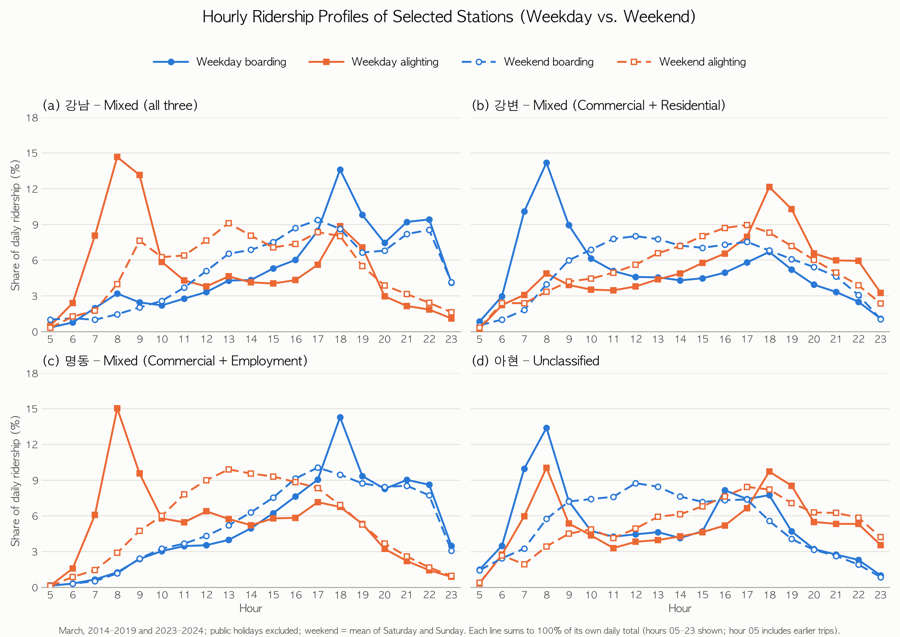

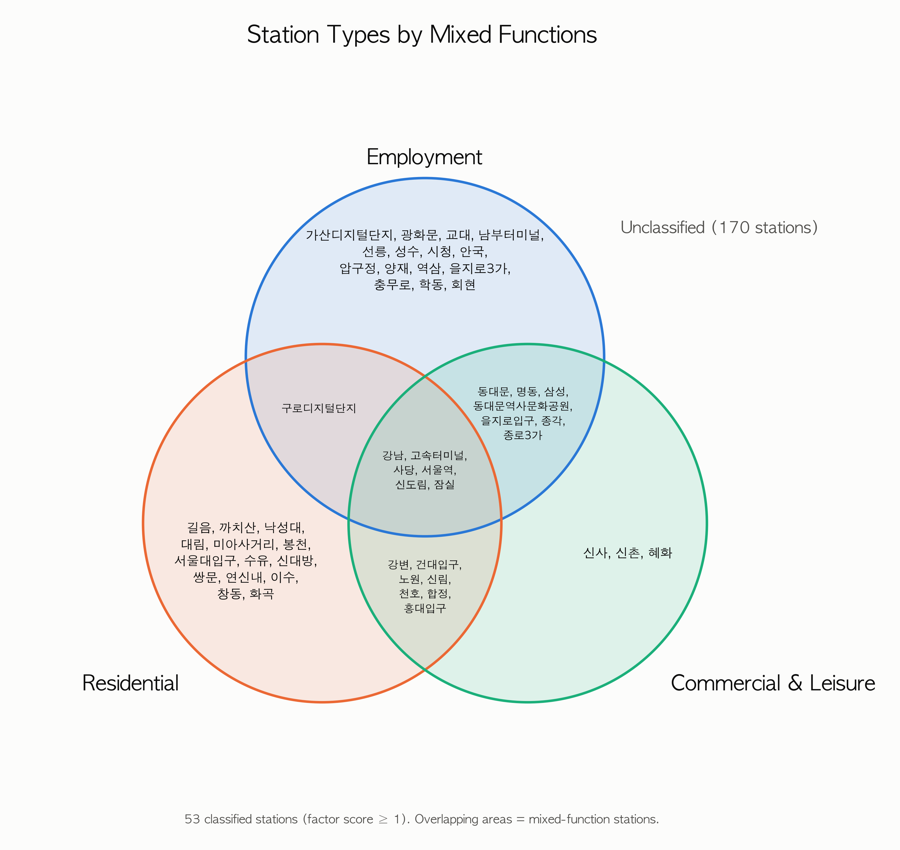

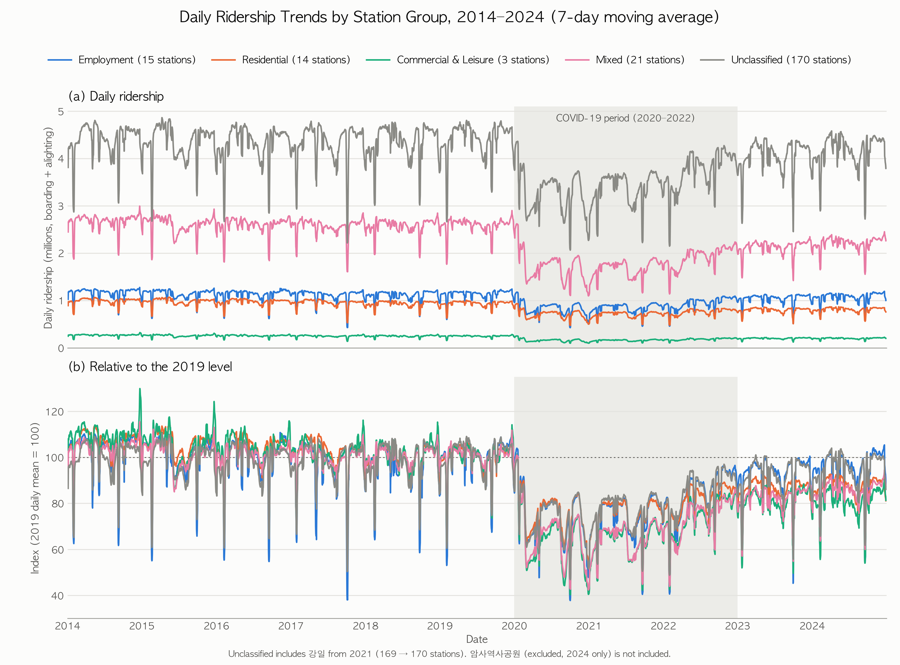

In [66]:
from IPython.display import display
from PIL import Image as PILImage
for _f in ['fig_hourly_profile_4stations.png', 'fig_station_type_venn.png', 'fig_group_daily_trend.png']:
    if (FIG / _f).exists():
        _im = PILImage.open(FIG / _f)
        _im.thumbnail((900, 900))        # 노트북 용량을 줄이려고 줄여서 보여 줌 (원본은 figures/에 300dpi로 저장됨)
        display(_im)

## 7단계: 테스트 연도(2025) 행 추가 — 데이터 준비만

테스트 연도(기본 2025) 추가: 파일 구조 확인 → 역명 통일 확인 → 서울 외 역 제외 → 일별 합계 → station_daily / group_daily에 붙임.

중단 조건: 형식이 이전과 다르거나, 새로 생기거나 이름이 바뀐 역이 있으면 아무것도 바꾸지 않고
new_year_check_{year}.csv 에 목록을 저장한 뒤 종료(종료 코드 2). 사용자 확인 후 --accept-names 로 다시 실행.
- 역 유형은 다시 분류하지 않고 station_type.csv를 그대로 붙임 (학습 때 없던 역은 'New (not in training)')
- split 열: 2014~2024 = train, 2025 = test

**`header_of`**: 원본 파일의 컬럼 이름(헤더)을 읽습니다.

In [67]:
def header_of(fname):
    if fname.endswith('.xlsx'):
        return None
    return tuple(pd.read_csv(RAW / fname, encoding='cp949', nrows=0).columns)

**`check_format`**: 형식 점검 결과(정보, 문제)

In [68]:
def check_format(year, s, n_raw):
    """형식 점검 결과(정보, 문제)"""
    info, issues = [], []
    f = raw_file(year)
    h = header_of(f)
    known = {y: header_of(raw_file(y)) for y in range(2014, year) if y in TRAIN_YEARS or y == year - 1}
    same = [y for y, hh in known.items() if hh is not None and hh == h]
    info.append(f'파일 {nfc(f)} | 컬럼 {len(h)}개 | 이전 연도 중 같은 헤더: {same or "없음"}')
    if not same:
        issues.append(dict(issue='새로운 파일 형식(헤더가 이전 어느 해와도 다름)', detail=str(h)))
    blank = n_raw - len(s)
    info.append(f'원본 {n_raw:,}행 중 빈 행 {blank}개 제외 -> {len(s):,}행')
    d0, d1 = s.date.min(), s.date.max()
    miss = pd.date_range(d0, d1).difference(pd.DatetimeIndex(s.date.unique()))
    info.append(f'기간 {d0.date()} ~ {d1.date()} ({s.date.nunique()}일, 누락일 {len(miss)})')
    if len(miss) or d1 != pd.Timestamp(year, 12, 31) or d0 != pd.Timestamp(year, 1, 1):
        issues.append(dict(issue='연도 전체가 아니거나 누락일 있음', detail=f'{d0.date()}~{d1.date()}, 누락 {len(miss)}일'))
    info.append(f'방향 {sorted(s.io.unique())} | 노선 {sorted(s.line.unique())} | 시간대 NaN {int(s[HOURS].isna().sum().sum())} | 음수 {int((s[HOURS] < 0).sum().sum())} | 중복 {int(s.duplicated(["date", "line", "stn_no", "io"]).sum())}')
    if s[HOURS].isna().any().any() or (s[HOURS] < 0).any().any() or s.duplicated(['date', 'line', 'stn_no', 'io']).any() or sorted(s.io.unique()) != ['승차', '하차']:
        issues.append(dict(issue='값 이상(NaN/음수/중복/방향 값)', detail=info[-1]))
    return info, issues

**`check_names`**: station_map과 비교: 새 이름·이름 변경·부기명 변경·새 역번호·사라진 역

In [69]:
def check_names(year, A, SM):
    """station_map과 비교: 새 이름·이름 변경·부기명 변경·새 역번호·사라진 역"""
    S = A.groupby(['line', 'name_raw', 'stn_no']).agg(first_date=('date', 'min'), last_date=('date', 'max')).reset_index()
    SM = SM.assign(station_no=SM.station_no.astype(str))
    key = set(zip(SM.raw_name, SM.line))
    cur = SM.sort_values('end_date').drop_duplicates(['line', 'station_no'], keep='last').set_index(['line', 'station_no'])
    rows = []
    for r in S.itertuples():
        if (r.name_raw, r.line) in key:
            continue
        k = (r.line, r.stn_no)
        if k not in cur.index:
            rows.append(dict(issue='새로 생긴 역(기존에 없던 역번호)', line=r.line, station_no=r.stn_no, old_name='', new_name=r.name_raw, first_date=r.first_date.date(), last_date=r.last_date.date()))
            continue
        old = cur.loc[k]
        kind = '부기명 변경(정규화 이름 같음, 자동 대응 가능)' if base_name(old.raw_name) == base_name(r.name_raw) else '이름 변경(역번호 동일)'
        rows.append(dict(issue=kind, line=r.line, station_no=r.stn_no, old_name=old.raw_name, new_name=r.name_raw, first_date=r.first_date.date(), last_date=r.last_date.date(), standard_name_now=old.station))
    present = set(zip(S.name_raw, S.line))
    prev_end = pd.Timestamp(year - 1, 12, 31).date().isoformat()
    for r in SM[SM.end_date >= prev_end].itertuples():
        if (r.raw_name, r.line) not in present:
            rows.append(dict(issue='사라진 역(전년 말까지 있었는데 이 해에 없음)', line=r.line, station_no=r.station_no, old_name=r.raw_name, new_name='', first_date='', last_date=''))
    return S, pd.DataFrame(rows)

**`extend_station_map`**: 새 원본 이름을 기존 역에 대응시켜 station_map에 추가하고, 이 해에 나온 기존 이름의 종료일을 갱신. (policy='keep': 표준역명은 그대로)

In [70]:
def extend_station_map(SM, S, policy):
    """새 원본 이름을 기존 역에 대응시켜 station_map에 추가하고, 이 해에 나온 기존 이름의 종료일을 갱신. (policy='keep': 표준역명은 그대로)"""
    if policy != 'keep':
        raise NotImplementedError('표준역명을 새 이름으로 바꾸는 정책은 기존 산출물의 역 이름도 함께 바꿔야 해서 아직 지원하지 않음')
    SM = SM.copy()
    SM['station_no'] = SM.station_no.astype(str)
    add = []
    for r in S.itertuples():
        m = (SM.raw_name == r.name_raw) & (SM.line == r.line)
        if m.any():
            idx = SM[m].index
            SM.loc[idx, 'end_date'] = max(str(SM.loc[idx, 'end_date'].iloc[0]), str(r.last_date.date()))
            continue
        same_no = SM[(SM.line == r.line) & (SM.station_no == r.stn_no)]
        if same_no.empty:
            raise RuntimeError(f'새 역은 자동 처리하지 않음(소재지·유형 확인 필요): {r.line}호선 {r.name_raw} ({r.stn_no})')
        o = same_no.sort_values('end_date').iloc[-1]
        add.append(dict(raw_name=r.name_raw, normalized_name=strip_yeok(base_name(r.name_raw)), line=r.line, station_no=r.stn_no, station=o.station,
                        start_date=r.first_date.date(), end_date=r.last_date.date(), valid_days=(r.last_date - r.first_date).days + 1,
                        transfer_group_line_count=o.transfer_group_line_count, note=f'{r.first_date.year}년 새 표기(이전: {o.raw_name})', in_seoul=o.in_seoul, exclusion_reason=o.exclusion_reason))
    return pd.concat([SM, pd.DataFrame(add)], ignore_index=True) if add else SM

**`main`**: 2025년 원본의 형식·역 이름을 점검하고, 이름 대응을 확장해 `station_daily`, `group_daily`에 2025년(split=test) 행을 추가합니다. 2025년은 여기서 데이터로만 준비하며 **모델링에는 07번 노트북 전까지 쓰지 않습니다.**

In [71]:
def main(year=2025, accept_names=False, rename_policy='keep'):
    ensure_dirs()
    y = year
    s, n_raw = load_year(y)
    s.to_pickle(INTERIM / f'raw_{y}.pkl')
    info, issues = check_format(y, s, n_raw)
    print('\n'.join('  ' + i for i in info))
    SM = pd.read_csv(PROC / 'station_map.csv')
    A = load_interim([y])
    S, nm = check_names(y, A, SM)
    print(f'  역(노선·이름) {len(S)}개 | 이름 점검 결과 {len(nm)}건')
    out = pd.concat([pd.DataFrame(issues), nm], ignore_index=True)
    if len(out):
        out.to_csv(PROC / f'new_year_check_{y}.csv', index=False, encoding='utf-8-sig')
        print(out.to_string(index=False))
    if len(out) and not accept_names:
        print(f'\n중단: 위 항목을 확인한 뒤 --accept-names 로 다시 실행. 목록: {PROC / f"new_year_check_{y}.csv"}')
        sys.exit(2)
    if any(i['issue'].startswith(('새로운 파일 형식', '연도 전체', '값 이상')) for i in issues):
        print('\n중단: 파일 형식/값 문제는 --accept-names 로 넘어갈 수 없음')
        sys.exit(2)

    # ---- 이름 대응 확장 -> 서울 외 제외 -> 시간대/일별
    SM2 = extend_station_map(SM, S, rename_policy)
    SM2.to_csv(PROC / 'station_map.csv', index=False, encoding='utf-8-sig')
    T, n_zero, one = build_hourly(A, SM2)
    D = calendar(daily_from_hourly(T))
    D = attach_type(D, pd.read_csv(PROC / 'station_type.csv'))
    G = group_daily(D)
    D0 = pd.read_csv(PROC / 'station_daily.csv.gz', parse_dates=['date'])
    G0 = pd.read_csv(PROC / 'group_daily.csv', parse_dates=['date'])
    D0 = D0[D0.date.dt.year != y]
    G0 = G0[G0.date.dt.year != y]
    for c in COLS:
        if c not in D0.columns:
            raise RuntimeError(f'기존 station_daily에 {c} 열이 없음: step5를 먼저 실행')
    write(pd.concat([D0, D[COLS]], ignore_index=True), pd.concat([G0, G], ignore_index=True))
    new_st = sorted(set(D.station) - set(pd.read_csv(PROC / 'station_type.csv').station))
    print(f'\n{y}년 추가: station_daily {len(D):,}행 ({D.station.nunique()}개 역), group_daily {len(G)}행 | 역-일 합계 0 제거 {n_zero} | 한쪽만 0 NaN {len(one)} | 학습에 없던 역 {new_st}')
    print(D.groupby('group').station.nunique().to_dict())

**실행** (원본이 있을 때만): 새·변경된 역 이름(3건)은 확인을 마쳤으므로 `accept_names=True`로 진행하고, 표준역명은 기존 이름을 유지합니다(`rename_policy='keep'`). 2025년 행은 `station_daily`/`group_daily`에 split=test로 들어가지만 **모델링에는 07번 노트북 전까지 쓰지 않습니다.**

In [72]:
if RAW_OK:
    main(year=2025, accept_names=True, rename_policy='keep')
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

  파일 서울교통공사_역별 일별 시간대별 승하차인원_20251231.csv | 컬럼 26개 | 이전 연도 중 같은 헤더: [2023]
  원본 199,424행 중 빈 행 134개 제외 -> 199,290행
  기간 2025-01-01 ~ 2025-12-31 (365일, 누락일 0)
  방향 ['승차', '하차'] | 노선 ['1', '2', '3', '4', '5', '6', '7', '8'] | 시간대 NaN 0 | 음수 0 | 중복 0


  역(노선·이름) 276개 | 이름 점검 결과 3건
                      issue  line station_no old_name   new_name first_date  last_date standard_name_now
              이름 변경(역번호 동일)     4        409      당고개        불암산 2025-04-01 2025-12-31               당고개
부기명 변경(정규화 이름 같음, 자동 대응 가능)     4        428      삼각지 삼각지(전쟁기념관) 2025-04-01 2025-12-31               삼각지
부기명 변경(정규화 이름 같음, 자동 대응 가능)     6       2629      삼각지 삼각지(전쟁기념관) 2025-04-01 2025-12-31               삼각지



2025년 추가: station_daily 81,760행 (224개 역), group_daily 1825행 | 역-일 합계 0 제거 0 | 한쪽만 0 NaN 0 | 학습에 없던 역 []
{'Commercial & Leisure': 3, 'Employment': 15, 'Excluded': 1, 'Mixed': 21, 'Residential': 14, 'Unclassified': 170}


산출물 확인

In [73]:
show_files(['station_daily.csv.gz', 'group_daily.csv', 'new_year_check_2025.csv'])

,file,rows,cols
0,station_daily.csv.gz,975289,19
1,group_daily.csv,21915,7
2,new_year_check_2025.csv,3,8


## 8단계: ASOS 서울(108) 시간자료 → 일별 날씨 (2014~2025)

8단계: 기상청 ASOS 서울(108) 시간자료 -> 일별 날씨 (2014~2025).

- 입력: rawdata/asos/OBS_ASOS_TIM_*.csv (cp949). 지점 108(서울)만 사용, 2026년 이후 시각은 버림
- 일별 변환은 개인 프로젝트의 build_merged.py와 같은 기준:
  강수량·적설 빈칸은 0으로 보고(rain_mm=일 합계, snow_depth_max=일 최대), 관측 시간 수가 20 미만인 날은 값을 NaN으로 둠
  (3시간신적설도 빈칸=0, snow_new_cm=일 합계)
- 습도(%)는 일 평균(rh_mean). 체감온도는 기상청 여름철 체감온도 식(Ta=기온, RH=습도)으로 시간별로 계산한 뒤 일 최대(feels_like_max):
    Tw = Ta*atan(0.151977*sqrt(RH+8.313659)) + atan(Ta+RH) - atan(RH-1.676331) + 0.00391838*RH**1.5*atan(0.023101*RH) - 4.686035
    체감온도 = -0.2442 + 0.55399*Tw + 0.45535*Ta - 0.0022*Tw**2 + 0.00278*Tw*Ta + 3.0
  (여름철 식이라 5~9월에만 값을 두고 10~4월은 NaN. 기온이나 습도가 빈 시간은 그 시간의 체감온도를 NaN으로 둠)
- 강수량 QC플래그 9인 시간 수는 precip_flag9_hours로 따로 남김(값은 그대로 사용)
- 연도별 시간 빈틈 점검표를 weather_daily_check.csv로 저장

상수·설정값을 정의합니다: `ASOS`, `STATION`, `MIN_HOURS`, `WEATHER_DAILY_COLS`.

In [74]:
ASOS = RAW / 'asos'
STATION = 108
START, END = '2014-01-01', '2025-12-31'
MIN_HOURS = 20                # 하루 관측 시간 수가 이보다 적으면 그날 값은 NaN
WEATHER_DAILY_COLS = ['date', 'temp_mean', 'tmax', 'tmin', 'rain_mm', 'snow_depth_max', 'snow_new_cm', 'wind_mean', 'rh_mean', 'feels_like_max', 'precip_flag9_hours']

**`feels_like`**: 기상청 여름철 체감온도(℃).

In [75]:
def feels_like(ta, rh):
    """기상청 여름철 체감온도(℃)."""
    tw = (ta * np.arctan(0.151977 * np.sqrt(rh + 8.313659)) + np.arctan(ta + rh) - np.arctan(rh - 1.676331)
          + 0.00391838 * rh ** 1.5 * np.arctan(0.023101 * rh) - 4.686035)
    return -0.2442 + 0.55399 * tw + 0.45535 * ta - 0.0022 * tw ** 2 + 0.00278 * tw * ta + 3.0

**`load_hourly`**: ASOS 시간별 자료(서울 108)를 읽어 합칩니다.

In [76]:
def load_hourly():
    fs = sorted(f for f in ASOS.glob('OBS_ASOS_TIM_*.csv'))
    w = pd.concat([pd.read_csv(f, encoding='cp949') for f in fs], ignore_index=True)
    n0 = len(w)
    w = w[w['지점'] == STATION].copy()                        # 2015년 파일에 섞인 관악산(116) 행 등 제거
    w['dt'] = pd.to_datetime(w['일시'])
    w = w[(w.dt >= START) & (w.dt < pd.Timestamp(END) + pd.Timedelta(days=1))]
    dup = w.dt.duplicated().sum()
    if dup:
        raise ValueError(f'중복 시각 {dup}건')
    print(f'파일 {len(fs)}개, 읽은 행 {n0}, 지점 {STATION}·{START}~{END} 행 {len(w)}')
    return w

**`to_daily`**: 시간별 날씨를 일별로 바꿉니다 (강수·적설 빈칸은 0, 관측 20시간 미만인 날은 NaN, 체감온도는 5~9월만).

In [77]:
def to_daily(w):
    w = w.assign(date=w.dt.dt.normalize(),
                 rain=w['강수량(mm)'].fillna(0),             # 빈칸 = 강수 없음
                 snow=w['적설(cm)'].fillna(0),               # 빈칸 = 적설 없음
                 snow_new=w['3시간신적설(cm)'].fillna(0),    # 빈칸 = 신적설 없음
                 fl=feels_like(w['기온(°C)'], w['습도(%)']))
    g = w.groupby('date')
    wd = pd.DataFrame({
        'temp_mean': g['기온(°C)'].mean(), 'tmax': g['기온(°C)'].max(), 'tmin': g['기온(°C)'].min(),
        'rain_mm': g.rain.sum(), 'snow_depth_max': g.snow.max(), 'snow_new_cm': g.snow_new.sum(),
        'wind_mean': g['풍속(m/s)'].mean(), 'rh_mean': g['습도(%)'].mean(), 'feels_like_max': g.fl.max(),
        'precip_flag9_hours': g['강수량 QC플래그'].apply(lambda s: int((s == 9).sum())),
        'hours': g['기온(°C)'].count(),
    })
    wd = wd.reindex(pd.date_range(START, END, name='date'))
    wd['hours'] = wd.hours.fillna(0).astype(int)
    wd['precip_flag9_hours'] = wd.precip_flag9_hours.fillna(0).astype(int)
    partial = wd.hours < MIN_HOURS
    wd.loc[partial, WEATHER_DAILY_COLS[1:-1]] = np.nan
    wd.loc[~wd.index.month.isin(range(5, 10)), 'feels_like_max'] = np.nan      # 여름철 식: 5~9월만
    return wd

**`hour_check`**: 연도별: 있어야 할 시간 수, 실제 시간 수, 12월 31일 시간 수, 1월 1일 0시 유무, 값이 NaN인 날 수

In [78]:
def hour_check(w, wd):
    """연도별: 있어야 할 시간 수, 실제 시간 수, 12월 31일 시간 수, 1월 1일 0시 유무, 값이 NaN인 날 수"""
    rows = []
    for y in range(2014, 2026):
        wy = w[w.dt.dt.year == y]
        exp = len(pd.date_range(f'{y}-01-01', f'{y}-12-31 23:00', freq='h'))
        have = pd.DatetimeIndex(wy.dt)
        miss = pd.date_range(f'{y}-01-01', f'{y}-12-31 23:00', freq='h').difference(have)
        d31 = int((wy.dt.dt.strftime('%m-%d') == '12-31').sum())
        rows.append({'year': y, 'expected_hours': exp, 'present_hours': len(wy), 'missing_hours': len(miss),
                     'dec31_hours': d31, 'jan1_0000_present': int(pd.Timestamp(y, 1, 1) in have),
                     'missing_other_than_dec31_jan1_0000': int(sum(not ((m.month == 12 and m.day == 31) or (m.month == 1 and m.day == 1 and m.hour == 0)) for m in miss)),
                     'blank_temp_hours': int(wy['기온(°C)'].isna().sum()), 'blank_rh_hours': int(wy['습도(%)'].isna().sum()),
                     'days_nan': int(wd.loc[str(y)].temp_mean.isna().sum())})
    return pd.DataFrame(rows)

**실행** (`rawdata/asos/`가 있을 때만): 일별 날씨(`weather_daily.csv`)와 시간 빈틈 점검표(`weather_daily_check.csv`)를 저장합니다.

In [79]:
if RAW_OK:
    ensure_dirs()
    w = load_hourly()
    wd = to_daily(w)
    out = wd.reset_index()[WEATHER_DAILY_COLS]
    out.to_csv(PROC / 'weather_daily.csv', index=False, encoding='utf-8-sig', float_format='%.4f')
    chk = hour_check(w, wd)
    chk.to_csv(PROC / 'weather_daily_check.csv', index=False, encoding='utf-8-sig')
    pd.set_option('display.width', 250)
    print(chk.to_string(index=False))
    print(out.shape, out.date.min().date(), out.date.max().date())
    print('NaN 열별:', out.isna().sum()[lambda s: s > 0].to_dict())
    print('NaN인 날 수:', int(out.temp_mean.isna().sum()), '| 전부 12/31인가:', bool((out[out.temp_mean.isna()].date.dt.strftime('%m-%d') == '12-31').all()))
else:
    print('rawdata가 없어 이 단계는 건너뜁니다 (처리된 파일을 아래에서 읽기만 합니다).')

파일 12개, 읽은 행 105193, 지점 108·2014-01-01~2025-12-31 행 105192


 year  expected_hours  present_hours  missing_hours  dec31_hours  jan1_0000_present  missing_other_than_dec31_jan1_0000  blank_temp_hours  blank_rh_hours  days_nan
 2014            8760           8760              0           24                  1                                   0                 0              12         0
 2015            8760           8760              0           24                  1                                   0                 1              31         0
 2016            8784           8784              0           24                  1                                   0                 0               0         0
 2017            8760           8760              0           24                  1                                   0                 4               4         0
 2018            8760           8760              0           24                  1                                   0                 1               0         0
 2019           

산출물 확인

In [80]:
show_files(['weather_daily.csv', 'weather_daily_check.csv'])

,file,rows,cols
0,weather_daily.csv,4383,11
1,weather_daily_check.csv,12,10


## 9단계: 모델 입력 데이터 (단독형 역 9개 × 2014-01-01~2025-12-31 일별)

9단계: 모델 입력 데이터 (단독형 역 9개 × 2014-01-01~2025-12-31 일별).

- 대상: Employment(시청·역삼·선릉), Commercial & Leisure(신촌·혜화·신사), Residential(서울대입구·수유·연신내)
- station_daily.csv.gz에서 뽑고(날짜 빈틈 없이 재인덱스), 역별 요인점수 3개와 자치구를 붙임
- split: 2014~2023 train, 2024 validation, 2025 test
- 가리기용 0/1 열: holiday, labor_day(매년 5/1), myeongjeol_pm2(설날·추석 당일 ±2일), covid, mers, strike, rally_cityhall(시청역만)
- 계단 더미(시행일부터 1): fare_2015/fare_2023/fare_2025/climate_card(전 역), sillim_line(서울대입구만), sinbundang_ext(신사만)
- 계절 더미: summer_vacation(매년 7월 마지막 월요일 ~ 8월 둘째 일요일 = 1, 전 역)
- weather_daily.csv를 date로 left join
- 특보 열(alert_heat/cold/rain/snow, any_alert): 팀 저장소의 서울_날씨특보_활성상태_일별_onehot.csv(rawdata/alert/ 또는 저장소 루트)를 date로 붙임.
  서울 전체 기준이라 9개 역 모두 같은 값(권역 미구분, 주의보·경보 단계 구분 없음). 파일이 시작하는 2014-01-08 앞의 2014-01-01~07은 특보 여부를 알 수 없어
  alert_*를 비워 두고(NaN) alert_unknown=1(가리기용)

상수·설정값을 정의합니다: `STATION_DISTRICT`, `STRIKE`, `RALLY`, `STEPS`, `STATION_STEPS`, `MYEONGJEOL_DAYS`, `SEASONS`, `MASKS`, `WEATHER`, `ALERT_FOUR`, `ALERTS`, `ALERT_NAME`, `ALERT_MAP`, `ALERT_PATHS`.

In [81]:
START, END = '2014-01-01', '2025-12-31'
# 역 -> 자치구 (특보 권역 연결용)
STATION_DISTRICT = {'시청': '중구', '역삼': '강남구', '선릉': '강남구',
            '신촌': '서대문구', '혜화': '종로구', '신사': '강남구',
            '서울대입구': '관악구', '수유': '강북구', '연신내': '은평구'}
STRIKE = [('2016-09-27', '2016-09-29'), ('2022-11-30', '2022-11-30'), ('2023-11-09', '2023-11-10')]
RALLY = [('2016-10-29', '2017-04-29'), ('2024-12-07', '2025-04-05')]       # 시청역, 토요일만
STEPS = {'fare_2015': '2015-06-27', 'fare_2023': '2023-10-07', 'fare_2025': '2025-06-28', 'climate_card': '2024-01-27'}
STATION_STEPS = {'sillim_line': ('서울대입구', '2022-05-28'), 'sinbundang_ext': ('신사', '2022-05-28')}
MYEONGJEOL_DAYS = 2                                           # 명절 당일 앞뒤로 가리는 일수 (원래 1이었다가 연휴 직전 토요일까지 가리려고 2로 넓힘)
SEASONS = ['summer_vacation']
MASKS = ['holiday', 'labor_day', 'myeongjeol_pm2', 'covid', 'mers', 'strike', 'rally_cityhall', 'alert_unknown']
WEATHER = ['temp_mean', 'tmax', 'tmin', 'rain_mm', 'snow_depth_max', 'snow_new_cm', 'wind_mean', 'rh_mean', 'feels_like_max', 'precip_flag9_hours']
ALERT_FOUR = ['alert_heat', 'alert_cold', 'alert_rain', 'alert_snow']
ALERTS = ALERT_FOUR + ['any_alert']
ALERT_NAME = '서울_날씨특보_활성상태_일별_onehot.csv'
ALERT_MAP = {'한파': 'alert_cold', '폭염': 'alert_heat', '호우': 'alert_rain', '대설': 'alert_snow'}
ALERT_PATHS = [RAW / 'alert' / ALERT_NAME, ROOT / ALERT_NAME]

**`summer_vacation_range`**: 7월의 마지막 월요일 ~ 8월의 두 번째 일요일

In [82]:
def summer_vacation_range(year):
    """7월의 마지막 월요일 ~ 8월의 두 번째 일요일"""
    jul = pd.date_range(f'{year}-07-01', f'{year}-07-31')
    start = jul[jul.dayofweek == 0].max()
    aug = pd.date_range(f'{year}-08-01', f'{year}-08-31')
    return start, aug[aug.dayofweek == 6][1]

**`in_ranges`**: 날짜가 주어진 구간 안에 있으면 1인 열을 만듭니다.

In [83]:
def in_ranges(dates, ranges):
    m = pd.Series(False, index=dates.index)
    for a, b in ranges:
        m |= (dates >= a) & (dates <= b)
    return m.astype(int)

**`build`**: 9개 역의 모델 입력 표를 만듭니다 (가리기 열, 더미, 날씨, 특보 붙이기).

In [84]:
def build():
    sd = pd.read_csv(PROC / 'station_daily.csv.gz', parse_dates=['date'])
    sd = sd[sd.station.isin(STATION_DISTRICT) & (sd.date >= START) & (sd.date <= END)]
    assert sd.station.nunique() == len(STATION_DISTRICT) and not sd.duplicated(['station', 'date']).any()
    idx = pd.MultiIndex.from_product([list(STATION_DISTRICT), pd.date_range(START, END)], names=['station', 'date'])
    D = sd.set_index(['station', 'date']).reindex(idx).reset_index()      # 날짜 빈틈 없이
    D['district'] = D.station.map(STATION_DISTRICT)
    for c in ['group', 'score_commercial_leisure', 'score_residential', 'score_employment']:
        D[c] = D.groupby('station')[c].transform('first')
    y = D.date.dt.year
    D['split'] = np.where(y <= 2023, 'train', np.where(y == 2024, 'validation', 'test'))
    D['day_of_week'] = D.date.dt.day_name()
    D['is_weekend'] = (D.date.dt.dayofweek >= 5).astype(int)

    # ---- 가리기용 0/1
    cal = sd.drop_duplicates('date').set_index('date').holiday_name.reindex(pd.date_range(START, END)).fillna('')
    D['holiday'] = D.date.map(sd.drop_duplicates('date').set_index('date').is_public_holiday).fillna(0).astype(int)
    D['labor_day'] = ((D.date.dt.month == 5) & (D.date.dt.day == 1)).astype(int)         # 근로자의 날(법정 공휴일 아님, 업무지구는 사실상 휴일)
    day0 = cal.index[[any(t.strip() in ('설날', '추석') for t in n.split(';')) for n in cal]]      # 명절 당일
    near = set().union(*[set(day0 + pd.Timedelta(days=k)) for k in range(-MYEONGJEOL_DAYS, MYEONGJEOL_DAYS + 1)])
    D['myeongjeol_pm2'] = D.date.isin(near).astype(int)      # 당일 ±MYEONGJEOL_DAYS(=2)일
    D['covid'] = in_ranges(D.date, [('2020-02-01', '2022-04-30')])
    D['mers'] = in_ranges(D.date, [('2015-05-20', '2015-07-28')])
    D['strike'] = in_ranges(D.date, STRIKE)
    D['rally_cityhall'] = (in_ranges(D.date, RALLY) & (D.date.dt.dayofweek == 5) & (D.station == '시청')).astype(int)

    # ---- 계절 더미
    D['summer_vacation'] = in_ranges(D.date, [summer_vacation_range(y) for y in range(2014, 2026)])

    # ---- 계단 더미
    for k, d in STEPS.items():
        D[k] = (D.date >= d).astype(int)
    for k, (st, d) in STATION_STEPS.items():
        D[k] = ((D.date >= d) & (D.station == st)).astype(int)

    # ---- 날씨 (date로 left join)
    W = pd.read_csv(PROC / 'weather_daily.csv', parse_dates=['date'])
    n = len(D)
    D = D.merge(W, on='date', how='left')
    assert len(D) == n

    # ---- 특보 (서울 전체 기준, 모든 역 같은 값). 파일에 없는 날(2014-01-01~07)은 NaN + alert_unknown=1
    A = pd.read_csv(next(p for p in ALERT_PATHS if p.exists()), encoding='utf-8-sig', parse_dates=['날짜']).rename(columns={'날짜': 'date', **ALERT_MAP})
    n = len(D)
    D = D.merge(A[['date'] + ALERT_FOUR], on='date', how='left')
    assert len(D) == n
    D['alert_unknown'] = D.alert_heat.isna().astype(int)
    known = D[ALERT_FOUR].sum(axis=1, min_count=len(ALERT_FOUR))
    D['any_alert'] = (known > 0).astype('Int64').where(known.notna())
    for c in ALERT_FOUR:
        D[c] = D[c].astype('Int64')

    cols = ['station', 'district', 'date', 'split', 'boarding', 'alighting', 'total', 'flag_one_side_zero', 'day_of_week', 'is_weekend', 'group',
            'score_commercial_leisure', 'score_residential', 'score_employment'] + MASKS + list(STEPS) + SEASONS + list(STATION_STEPS) + WEATHER + ALERTS
    return D[cols]

**`summary`**: 역별로 가리기 열이 1인 날 수와 total 결측 수를 셉니다.

In [85]:
def summary(D):
    S = D.groupby('station', sort=False).agg(**{c: (c, 'sum') for c in MASKS}, total_nan=('total', lambda s: int(s.isna().sum())))
    S.insert(0, 'days', D.groupby('station', sort=False).size())
    return S

**실행** (`station_daily.csv.gz`와 `weather_daily.csv`가 있을 때만): 모델 입력 표 `model_input_9stations.csv`를 저장하고 요약을 보여 줍니다.

In [86]:
if (PROC / 'station_daily.csv.gz').exists() and (PROC / 'weather_daily.csv').exists():
    ensure_dirs()
    D = build()
    out = D.copy()
    out['date'] = out.date.dt.date
    out.to_csv(PROC / 'model_input_9stations.csv', index=False, encoding='utf-8-sig')
    print(D.shape, D.date.min().date(), D.date.max().date())
    print(D.groupby('split').date.agg(['min', 'max', 'nunique']).to_string())
    print(summary(D).to_string())
    print('summer_vacation:', {y: (str(a.date()), str(b.date()), (b - a).days + 1) for y in range(2014, 2026) for a, b in [summer_vacation_range(y)]})
    print('NaN 열별:', D.isna().sum()[lambda s: s > 0].to_dict())
else:
    print('station_daily.csv.gz가 없어(용량 때문에 저장소에 없음) 이 단계는 건너뜁니다. 아래에서 처리된 파일을 읽습니다.')

(39447, 44) 2014-01-01 2025-12-31
                  min        max  nunique
split                                    
test       2025-01-01 2025-12-31      365
train      2014-01-01 2023-12-31     3652
validation 2024-01-01 2024-12-31      366
         days  holiday  labor_day  myeongjeol_pm2  covid  mers  strike  rally_cityhall  alert_unknown  total_nan
station                                                                                                         
시청       4383      215         12             120    820    70       6              45              7          0
역삼       4383      215         12             120    820    70       6               0              7          0
선릉       4383      215         12             120    820    70       6               0              7          0
신촌       4383      215         12             120    820    70       6               0              7          0
혜화       4383      215         12             120    820    70       6        

## 처리된 파일 읽기 (원본이 없어도 실행됨)

저장소에 포함된 처리 결과 `model_input_9stations.csv`와 `weather_daily.csv`를 읽어 구조를 확인합니다. 이후 노트북들은 이 파일들을 입력으로 씁니다.

In [87]:
mi = pd.read_csv(PROC / 'model_input_9stations.csv', parse_dates=['date'])
wd = pd.read_csv(PROC / 'weather_daily.csv', parse_dates=['date'])
print('model_input_9stations:', mi.shape, mi.date.min().date(), '~', mi.date.max().date(), '| 역', mi.station.nunique(), '개')
print('weather_daily:', wd.shape, wd.date.min().date(), '~', wd.date.max().date())
print('열:', list(mi.columns))
mi.head()

model_input_9stations: (39447, 44) 2014-01-01 ~ 2025-12-31 | 역 9 개
weather_daily: (4383, 11) 2014-01-01 ~ 2025-12-31
열: ['station', 'district', 'date', 'split', 'boarding', 'alighting', 'total', 'flag_one_side_zero', 'day_of_week', 'is_weekend', 'group', 'score_commercial_leisure', 'score_residential', 'score_employment', 'holiday', 'labor_day', 'myeongjeol_pm2', 'covid', 'mers', 'strike', 'rally_cityhall', 'alert_unknown', 'fare_2015', 'fare_2023', 'fare_2025', 'climate_card', 'summer_vacation', 'sillim_line', 'sinbundang_ext', 'temp_mean', 'tmax', 'tmin', 'rain_mm', 'snow_depth_max', 'snow_new_cm', 'wind_mean', 'rh_mean', 'feels_like_max', 'precip_flag9_hours', 'alert_heat', 'alert_cold', 'alert_rain', 'alert_snow', 'any_alert']


,station,district,date,split,boarding,alighting,total,flag_one_side_zero,day_of_week,is_weekend,...,snow_new_cm,wind_mean,rh_mean,feels_like_max,precip_flag9_hours,alert_heat,alert_cold,alert_rain,alert_snow,any_alert
0,시청,중구,2014-01-01,train,20936.0,17490.0,38426.0,0,Wednesday,0,...,0.0,3.7167,54.9583,NaN,13,NaN,NaN,NaN,NaN,NaN
1,시청,중구,2014-01-02,train,58808.0,59112.0,117920.0,0,Thursday,0,...,0.0,2.0458,35.0417,NaN,1,NaN,NaN,NaN,NaN,NaN
2,시청,중구,2014-01-03,train,61773.0,62436.0,124209.0,0,Friday,0,...,0.0,2.5083,52.6667,NaN,2,NaN,NaN,NaN,NaN,NaN
3,시청,중구,2014-01-04,train,33563.0,32832.0,66395.0,0,Saturday,1,...,0.0,2.5208,48.2083,NaN,0,NaN,NaN,NaN,NaN,NaN
4,시청,중구,2014-01-05,train,22211.0,20947.0,43158.0,0,Sunday,1,...,0.0,1.9875,47.9583,NaN,0,NaN,NaN,NaN,NaN,NaN
